# DataRetail 360 · Integración analítica confiable
## Evaluación Parcial 3 — IDY1102
**Estructuras y Visualización de Datos · Oscar Muñoz**  
**Entorno:** PostgreSQL de origen → Python/Pandas → SQL Server 2025.  
**Modalidad:** notebook técnico, ejecutable y documentado, con historial Git local.

Este trabajo integra las fuentes del caso para disponer información consistente de ventas,
clientes, productos, inventario y campañas. La empresa presenta cifras contradictorias porque
mezcla estados, impuestos, devoluciones, horarios y fuentes duplicadas. El objetivo de esta etapa
es construir la base analítica y demostrar calidad, integridad e historia temporal antes del consumo BI.

### Ruta de lectura y evaluación
| Criterio (20% cada uno) | Evidencia prevista |
|---|---|
| Modelo dimensional | Bus Matrix, diagrama, grano y diccionario |
| SCD | Tipos 1/2/3, justificación y pruebas temporales |
| Pipeline | Extracción, contratos, transformación, rechazos y logging |
| Almacenamiento | Bronze/Silver/Gold persistentes y SQL Server |
| Documentación | Decisiones, resultados, pruebas, linaje y Git |

### Ejecución
Crear el entorno con `python -m venv .venv`, instalar `requirements.txt`, seleccionar ese
intérprete en Jupyter/VS Code y completar `.env` a partir de `.env.example`.
Requiere PostgreSQL local poblado y SQL Server local con autenticación Windows y ODBC Driver 18.
Ejecutar las celdas en orden. La base `DataRetail360_DW` fue autorizada y creada previamente.
Los datos y logs se guardan en carpetas excluidas de Git. No se imprimen clientes ni credenciales.
El cuaderno es el entregable principal; el entorno, las bases y los archivos generados son sus dependencias.

## 1. Fuentes, alcance y decisiones
La fuente existente `idy1102_ep2` contiene 16 tablas `dr360_raw` que simulan los CSV,
Excel y sistemas del negocio. Se leen como tablas SQL; no se afirma haber recibido archivos
CSV/Excel independientes. Las cinco tablas `dr360_control` describen la simulación.
Las claves de persona real del generador **no se usan para resolver identidades**: hacerlo
convertiría una respuesta conocida de la simulación en una capacidad inexistente del negocio.

Se preservan las tablas de origen. La extracción se realiza en una transacción de solo lectura,
con una instantánea consistente. Las transformaciones ocurren en Pandas: es ETL hacia el DWH,
con conservación previa de crudos en Bronze. Medallion describe las capas de calidad, no obliga a usar Spark.

### Bus Matrix y granularidad
| Proceso | Una fila representa | Fecha | Producto | Sucursal | Cliente | Canal | Campaña |
|---|---|---|---|---|---|---|---|
| Ventas | Línea de documento + sistema POS/ECOM | Sí | Sí | Sí | Sí | Sí | Sí |
| Devoluciones | Registro de devolución | Sí | Sí | Sí | Sí | Sí | No |
| Inventario | Corte semanal × sucursal × producto | Sí | Sí | Sí | No | No | No |
| Campañas | Envío a un registro CRM | Sí | No | No | Sí | No | Sí |
| Web | Sesión | Sí | Producto principal | No | Sí | No | UTM |
| Reposición | Orden de reposición | Solicitud/recepción | Sí | Sí | No | No | No |

Las tablas de hechos no se unen directamente entre sí: se agregan al mismo grano antes de
comparar. El stock es semiaditivo: se suma entre productos/sucursales, **no entre cortes**.
La tabla de envíos no identifica un producto específico; no se inventa esa relación.
Los reportes legacy tienen grano agregado y quedan en una zona independiente de conciliación.

### Dimensiones y jerarquías
`dim_fecha`: día → mes → trimestre → año. `dim_producto`: producto → subcategoría → categoría
→ línea; marca es un atributo paralelo, no un nivel superior de categoría.
`dim_sucursal` y `dim_cliente`: comuna → región → país con roles geográficos distintos.
No se inventan provincia ni coordenadas que no existen en la fuente.
Se elige una constelación de estrellas con dimensiones conformadas; un copo de nieve separaría
geografías/categorías, pero añadiría joins sin necesidad para este volumen y uso académico.
Los miembros desconocidos usan clave 0; el canal digital sin local usa un miembro explícito.

### Contrato de indicadores
- Venta neta POS: documento EMITIDA, `monto_neto` sin IVA; se distribuye a líneas sin perder pesos.
- Venta neta e-commerce: ENTREGADO; mercadería `(subtotal-descuento)/1,19`, sin despacho,
  redondeada a CLP. La tasa 19% es un **supuesto del dataset**, no asesoría tributaria.
- Devoluciones: APROBADA y trazable al documento/producto; se descuentan una sola vez
  en fecha de devolución. Se explicita la base tributaria asumida de `monto_devuelto`.
- DEVUELTO/DEVOLUCION web no se reconoce como venta ENTREGADO. Sus devoluciones no se
  restan otra vez de ventas excluidas. Se informa esta limitación del modelo de estados de la fuente.
- Ticket promedio: venta antes de devoluciones / documentos distintos reconocidos.
- Cliente activo: persona resuelta con compra reconocida en los últimos seis meses respecto
  del corte del dataset; se excluye el cliente desconocido.
- Marketing: conversión reportada y retorno atribuido son indicadores de la plataforma;
  no se presentan como causalidad ni como ingreso conciliado con ventas.
- Inventario: riesgo de reposición según stock de sistema y mínimo; las diferencias con
  stock físico y antigüedad del conteo se reportan, no se corrigen inventando existencias.

Los errores de identidad se resuelven conservadoramente con RUT válido y correo único.
Los emparejamientos ambiguos quedan separados; similitud de nombres no basta para fusionar personas.

### Diagrama del modelo
La siguiente representación resume las relaciones. El archivo `modelo.drawio` contiene el
mismo diseño editable en diagrams.net. Cada hecho conserva su clave natural y las claves
sustitutas de las dimensiones aplicables.

```text
Fecha ─────┬── fact_ventas ───── Producto (SCD2)
Canal ─────┤       │                │
Campaña ───┤       ├── Sucursal ────┼── fact_inventario
Cliente ───┘       │                └── fact_reposicion
 (SCD2)            └── fact_devoluciones
   │
   ├── fact_marketing ── Campaña
   └── fact_web ──────── Producto / Campaña
```

SCD1 corrige atributos descriptivos; SCD2 conserva versiones de región/segmento del cliente
y categoría del producto; SCD3 mantiene zona actual/anterior de la sucursal.
La fuente solo contiene el estado actual: la primera carga **no reconstruye historia real**.
Se marca esa limitación y se demuestran cambios con casos controlados separados del negocio.

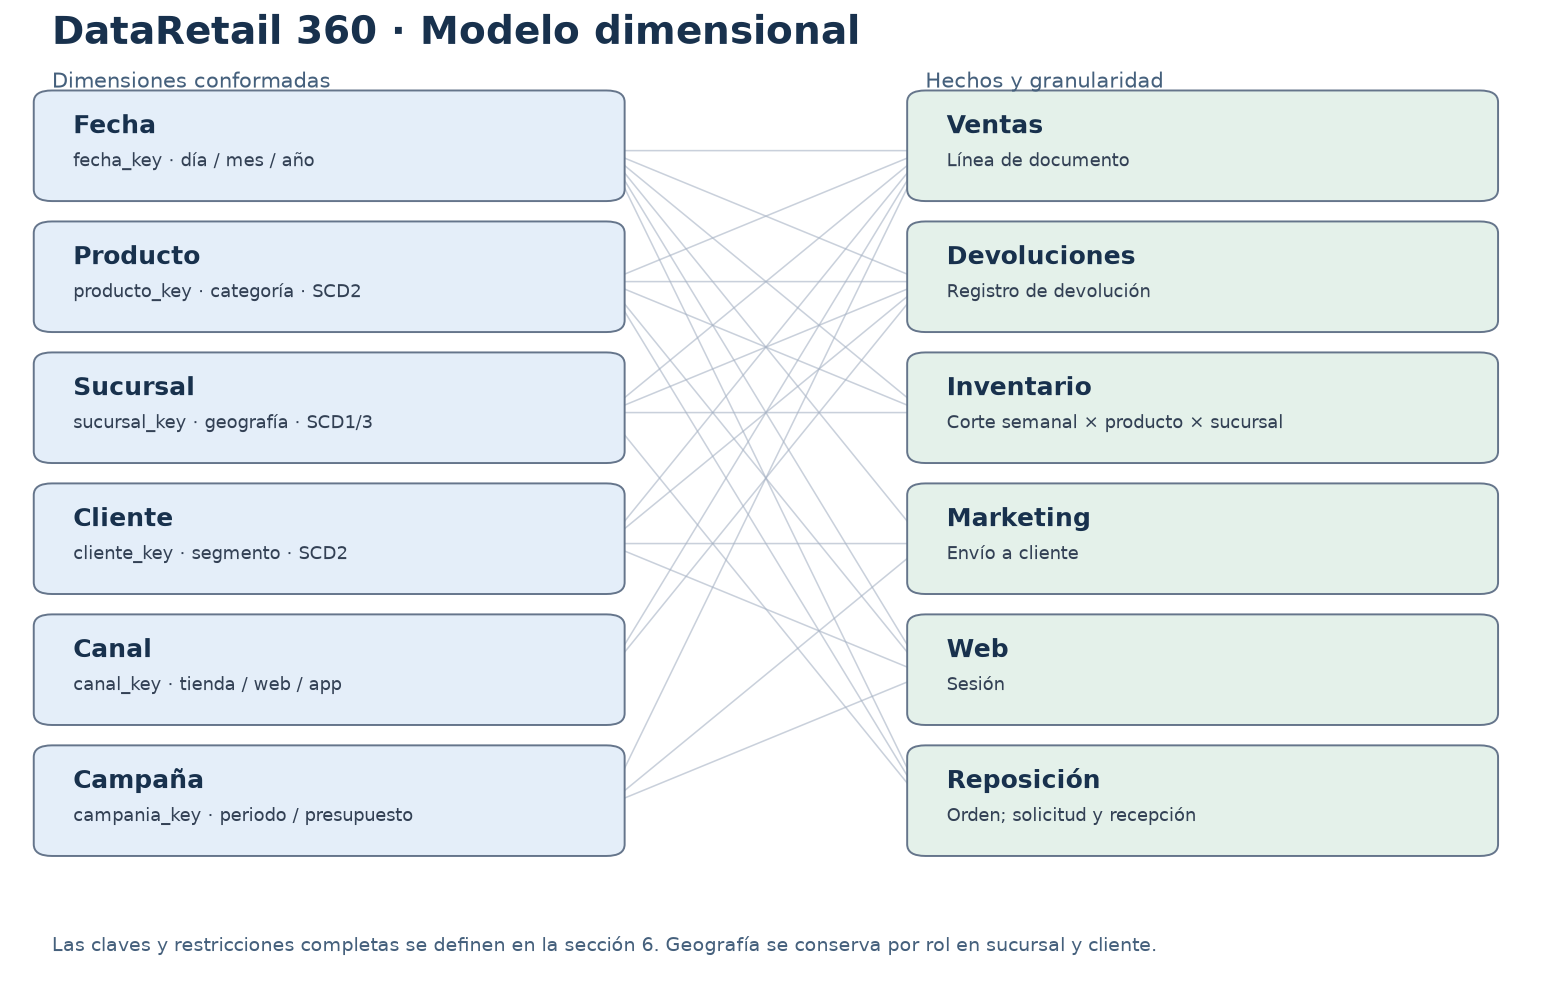

In [1]:
# Vista del modelo: todas las relaciones son dimensión 1 → N hecho.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import Image, display
from io import BytesIO
fig,ax=plt.subplots(figsize=(14,9));ax.set_xlim(0,1);ax.set_ylim(0,1);ax.axis('off')
dims=[('Fecha','fecha_key · día / mes / año'),('Producto','producto_key · categoría · SCD2'),
      ('Sucursal','sucursal_key · geografía · SCD1/3'),('Cliente','cliente_key · segmento · SCD2'),
      ('Canal','canal_key · tienda / web / app'),('Campaña','campania_key · periodo / presupuesto')]
facts_diagram=[('Ventas','Línea de documento',[0,1,2,3,4,5]),
 ('Devoluciones','Registro de devolución',[0,1,2,3,4]),('Inventario','Corte semanal × producto × sucursal',[0,1,2]),
 ('Marketing','Envío a cliente',[0,3,5]),('Web','Sesión',[0,1,3,5]),('Reposición','Orden; solicitud y recepción',[0,1,2])]
ys=[0.82-i*.135 for i in range(6)]
for i,(_,_,links) in enumerate(facts_diagram):
    for j in links:
        ax.add_patch(FancyArrowPatch((.39,ys[j]+.04),(.60,ys[i]+.04),arrowstyle='->',
                     mutation_scale=8,color='#a6b2c4',alpha=.6,linewidth=.8,zorder=1))
for x,items,color in [(.025,dims,'#e4eef9'),(.60,[(a,b) for a,b,_ in facts_diagram],'#e4f1ea')]:
    for y,(title,subtitle) in zip(ys,items):
        ax.add_patch(FancyBboxPatch((x,y),.365,.09,boxstyle='round,pad=0.012',
                                  facecolor=color,edgecolor='#65758b',zorder=2))
        ax.text(x+.014,y+.058,title,fontsize=13,weight='bold',color='#18314d',zorder=3)
        ax.text(x+.014,y+.024,subtitle,fontsize=9,color='#334155',zorder=3)
ax.text(.025,.97,'DataRetail 360 · Modelo dimensional',fontsize=20,weight='bold',color='#18314d')
ax.text(.025,.925,'Dimensiones conformadas',fontsize=11,color='#45607c')
ax.text(.60,.925,'Hechos y granularidad',fontsize=11,color='#45607c')
ax.text(.025,.035,'Las claves y restricciones completas se definen en la sección 6. Geografía se conserva por rol en sucursal y cliente.',fontsize=10,color='#45607c')
buffer=BytesIO();fig.savefig(buffer,format='png',bbox_inches='tight',dpi=140)
display(Image(data=buffer.getvalue()));plt.close(fig)


## 2. Extracción y capa Bronze

Se preserva una instantánea consistente del origen. Los hashes identifican lotes y evitan sobrescribir crudos; el manifiesto permite reconstruir el linaje. Un error de esquema detiene el proceso. Solo se reintentan errores de conexión.

In [2]:
# Contrato explícito obtenido del DDL proporcionado.
CONTRACT = {'pos_sucursales': ['id_sucursal', 'codigo_sucursal', 'nombre_sucursal', 'formato', 'direccion', 'comuna', 'region', 'zona', 'superficie_m2', 'fecha_apertura', 'fecha_cierre', 'estado', '_origen', '_fecha_carga'], 'pos_productos': ['codigo_producto', 'descripcion', 'linea_negocio', 'categoria', 'subcategoria', 'marca', 'codigo_barra', 'precio_lista', 'costo_unitario', 'estado', 'fecha_alta', 'fecha_baja', '_origen', '_fecha_carga'], 'pos_ventas_cabecera': ['id_boleta', 'tipo_documento', 'nro_documento', 'codigo_sucursal', 'nro_caja', 'fecha_hora', 'rut_cliente', 'medio_pago', 'codigo_cupon', 'monto_bruto', 'descuento_total', 'monto_neto', 'monto_iva', 'monto_total', 'estado', 'id_vendedor', '_origen', '_fecha_carga'], 'pos_ventas_detalle': ['id_boleta', 'nro_linea', 'codigo_producto', 'cantidad', 'precio_unitario', 'descuento', 'total_linea', '_origen', '_fecha_carga'], 'ecom_catalogo': ['sku_web', 'nombre_web', 'categoria_web', 'marca', 'vendedor', 'precio_web', 'codigo_pos_ref', 'ean', 'activo_web', 'fecha_publicacion', '_origen', '_fecha_carga'], 'ecom_cuentas': ['id_cuenta', 'email', 'nombre_completo', 'rut', 'telefono', 'comuna', 'fecha_creacion', 'ultimo_login', 'acepta_newsletter', '_origen', '_fecha_carga'], 'ecom_pedidos': ['id_pedido', 'id_cuenta', 'email_contacto', 'id_sesion', 'canal_venta', 'fecha_pedido_utc', 'estado_pedido', 'medio_pago', 'tipo_entrega', 'codigo_sucursal_retiro', 'comuna_despacho', 'codigo_cupon', 'subtotal', 'descuento', 'costo_despacho', 'total_pagado', 'fecha_entrega', '_origen', '_fecha_carga'], 'ecom_pedidos_detalle': ['id_pedido', 'nro_linea', 'sku_web', 'cantidad', 'precio_unitario', 'descuento', 'total_linea', '_origen', '_fecha_carga'], 'web_sesiones': ['id_sesion', 'id_cuenta', 'fecha_inicio_utc', 'dispositivo', 'fuente_trafico', 'utm_campaign', 'paginas_vistas', 'duracion_seg', 'sku_principal_visto', 'agrego_carrito', 'inicio_checkout', 'compro', '_origen', '_fecha_carga'], 'crm_clientes': ['id_cliente', 'rut', 'nombres', 'apellido_paterno', 'apellido_materno', 'email', 'telefono', 'fecha_nacimiento', 'genero', 'comuna', 'region', 'segmento_crm', 'canal_registro', 'fecha_registro', 'acepta_marketing', 'estado', '_origen', '_fecha_carga'], 'mkt_campanias': ['id_campania', 'codigo_campania', 'nombre_campania', 'tipo_campania', 'canal_objetivo', 'categoria_foco', 'segmento_objetivo', 'descuento_pct', 'fecha_inicio', 'fecha_fin', 'presupuesto_clp', 'responsable', '_origen', '_fecha_carga'], 'mkt_envios_campania': ['id_envio', 'id_campania', 'id_cliente', 'canal_envio', 'fecha_envio', 'entregado', 'abierto', 'fecha_apertura', 'click', 'convertido', 'monto_atribuido', '_origen', '_fecha_carga'], 'inv_stock_semanal': ['fecha_corte', 'codigo_sucursal', 'codigo_producto', 'stock_sistema', 'stock_fisico', 'stock_minimo', 'punto_reposicion', 'unidades_en_transito', 'fecha_ultimo_conteo', '_origen', '_fecha_carga'], 'inv_ordenes_reposicion': ['id_orden', 'codigo_sucursal', 'codigo_producto', 'fecha_solicitud', 'fecha_recepcion', 'cantidad_solicitada', 'cantidad_recibida', 'estado', '_origen', '_fecha_carga'], 'devoluciones': ['id_devolucion', 'canal_origen', 'id_documento_origen', 'codigo_producto', 'fecha_devolucion', 'cantidad', 'monto_devuelto', 'motivo', 'codigo_sucursal_recepcion', 'estado', '_origen', '_fecha_carga'], 'legacy_reporte_ventas_xlsx': ['archivo_origen', 'hoja', 'fila_excel', 'fecha', 'sucursal', 'linea', 'unidades', 'monto_venta', 'estado', 'responsable', 'observacion', '_origen', '_fecha_carga']}

In [3]:
# Configuración: credenciales fuera del notebook, rutas relativas y versiones verificables.
from pathlib import Path
from datetime import datetime, timezone
import os, json, hashlib, logging, uuid, time, re, unicodedata, subprocess
from decimal import Decimal, ROUND_HALF_UP
from contextlib import contextmanager
import pandas as pd
import numpy as np
import sqlalchemy as sa
from sqlalchemy import text
import pyarrow.parquet as pq
from dotenv import load_dotenv
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'EP3_DataRetail360.ipynb').exists():
    raise RuntimeError('Ejecutar desde la carpeta DataRetail360_EP3.')
load_dotenv(ROOT / '.env', encoding='utf-8-sig')
if not os.getenv('PGPASSWORD'):
    from getpass import getpass
    os.environ['PGPASSWORD'] = getpass('Contraseña PostgreSQL (no se muestra): ')
DATA = ROOT / 'data'
for folder in ['bronze', 'silver', 'gold', 'control', 'rechazos']:
    (DATA / folder).mkdir(parents=True, exist_ok=True)
(ROOT / 'logs').mkdir(exist_ok=True)
RUN_ID = uuid.uuid4().hex
LOG = logging.getLogger('dr360')
LOG.setLevel(logging.INFO)
for handler in LOG.handlers[:]:
    handler.close(); LOG.removeHandler(handler)
handler = logging.FileHandler(ROOT / 'logs' / f'{RUN_ID}.log', encoding='utf-8')
handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
LOG.addHandler(handler)
LOG.info('Inicio run=%s', RUN_ID)

PG = sa.create_engine(sa.URL.create('postgresql+psycopg',
    username=os.getenv('PGUSER','postgres'), password=os.environ['PGPASSWORD'],
    host=os.getenv('PGHOST','localhost'), port=int(os.getenv('PGPORT','5432')),
    database=os.getenv('PGDATABASE','idy1102_ep2')), hide_parameters=True,
    connect_args={'connect_timeout':10}, pool_pre_ping=True)
DW = sa.create_engine(sa.URL.create('mssql+pyodbc',
    host=os.getenv('MSSQL_SERVER','localhost'), database=os.getenv('MSSQL_DATABASE','DataRetail360_DW'),
    query={'driver':'ODBC Driver 18 for SQL Server','Trusted_Connection':'yes',
           'Encrypt':'yes','TrustServerCertificate':'yes'}),
    fast_executemany=True, hide_parameters=True, pool_pre_ping=True)
# TrustServerCertificate es una decisión del laboratorio local, no de producción.
with DW.connect() as conn:
    assert conn.scalar(text('SELECT DB_NAME()')) == 'DataRetail360_DW'
print('Conexiones configuradas; SQL Server disponible. Run:', RUN_ID)

# Natural keys de fuentes: permiten un orden reproducible y controles de duplicidad.
KEYS = {
 'pos_sucursales':['codigo_sucursal'], 'pos_productos':['codigo_producto'],
 'pos_ventas_cabecera':['id_boleta'], 'pos_ventas_detalle':['id_boleta','nro_linea'],
 'ecom_catalogo':['sku_web'], 'ecom_cuentas':['id_cuenta'],
 'ecom_pedidos':['id_pedido'], 'ecom_pedidos_detalle':['id_pedido','nro_linea'],
 'web_sesiones':['id_sesion'], 'crm_clientes':['id_cliente'],
 'mkt_campanias':['id_campania'], 'mkt_envios_campania':['id_envio'],
 'inv_stock_semanal':['fecha_corte','codigo_sucursal','codigo_producto'],
 'inv_ordenes_reposicion':['id_orden'], 'devoluciones':['id_devolucion'],
 'legacy_reporte_ventas_xlsx':['archivo_origen','hoja','fila_excel']}

def extract_snapshot():
    """Reintenta la extracción completa, nunca continúa una instantánea incompleta."""
    for attempt in range(3):
        try:
            raw, inventory = {}, []
            with PG.connect().execution_options(isolation_level='REPEATABLE READ') as conn:
                with conn.begin():
                    conn.execute(text('SET TRANSACTION READ ONLY'))
                    schema = pd.read_sql(text("SELECT table_name,column_name,data_type FROM information_schema.columns WHERE table_schema='dr360_raw' ORDER BY table_name,ordinal_position"), conn)
                    for name, key in KEYS.items():
                        cols = schema.loc[schema.table_name.eq(name),'column_name'].tolist()
                        if not set(CONTRACT[name]).issubset(cols):
                            raise ValueError(f'Contrato roto: {name}')
                        # Identificadores proceden de una lista fija, nunca de entrada del usuario.
                        frame = pd.read_sql(text(f'SELECT * FROM dr360_raw.{name} ORDER BY '+','.join(key)), conn)
                        digest = hashlib.sha256(pd.util.hash_pandas_object(frame,index=False).values.tobytes()).hexdigest()
                        path = DATA/'bronze'/name/f'{digest}.parquet'
                        path.parent.mkdir(exist_ok=True)
                        if not path.exists():
                            temp = path.with_suffix('.tmp'); frame.to_parquet(temp,index=False); temp.replace(path)
                        frame['_src_row'] = np.arange(len(frame),dtype='int64')
                        frame['_batch'] = digest
                        raw[name]=frame
                        inventory.append({'tabla':name,'filas':len(frame),'columnas':len(cols),'hash':digest,'archivo':str(path.relative_to(ROOT))})
                        LOG.info('extract tabla=%s filas=%d',name,len(frame))
                    # Solo metadatos del generador; no se extraen claves de personas reales.
                    controls={n:pd.read_sql(text(f'SELECT * FROM dr360_control.{n}'),conn) for n in
                              ['config_generacion','definiciones_kpi_por_area','problemas_calidad_inyectados']}
            return raw, pd.DataFrame(inventory), schema, controls
        except sa.exc.OperationalError:
            LOG.warning('Falla transitoria de extracción intento=%d',attempt+1)
            if attempt==2: raise
            time.sleep(2**attempt)
        except Exception as exc:
            LOG.error('Extracción detenida tipo=%s',type(exc).__name__)
            raise

raw, inventory, source_schema, controls = extract_snapshot()
manifest={'run_id':RUN_ID,'extracted_at_utc':datetime.now(timezone.utc).isoformat(),
          'sources':inventory.to_dict('records')}
(DATA/'control'/f'{RUN_ID}.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
source_schema.to_parquet(DATA/'control'/'source_schema.parquet',index=False)
display(inventory[['tabla','filas','columnas']])
print('Filas extraídas:',int(inventory.filas.sum()))

Conexiones configuradas; SQL Server disponible. Run: 0259ff6321b04396a2c5d052dd8709bf


,tabla,filas,columnas
0,pos_sucursales,46,14
1,pos_productos,2500,14
2,pos_ventas_cabecera,278593,18
3,pos_ventas_detalle,555230,9
4,ecom_catalogo,2190,12
5,ecom_cuentas,39184,11
6,ecom_pedidos,57015,19
7,ecom_pedidos_detalle,95197,9
8,web_sesiones,500003,14
9,crm_clientes,63586,18


Filas extraídas: 3438326


## 3. Calidad e integración Silver

Cada regla produce evidencia. Se separan duplicados, conflictos y rechazos; no se pierde una fila sin contabilizarla. La identidad y la homologación conservan incertidumbre cuando no hay evidencia suficiente.

In [4]:
# Funciones de normalización: reglas explícitas y reutilizables, no correcciones silenciosas.
def norm(value):
    if pd.isna(value): return ''
    return ''.join(c for c in unicodedata.normalize('NFKD',str(value).strip().upper()) if not unicodedata.combining(c))

def norm_series(s):
    lookup={v:norm(v) for v in s.dropna().unique()}
    return s.map(lookup).fillna('')

def code_series(s):
    return norm_series(s).str.replace(r'[^A-Z0-9]','',regex=True)

def rut_valid(value):
    x=re.sub(r'[^0-9K]','',norm(value))
    if len(x)<2: return None
    digits,dv=x[:-1],x[-1]
    if not digits.isdigit() or int(digits)==0: return None
    total=sum(int(n)*(2+i%6) for i,n in enumerate(reversed(digits)))
    check=11-total%11
    return digits+'-'+dv if dv==('0' if check==11 else 'K' if check==10 else str(check)) else None

def rut_series(s):
    return s.map({v:rut_valid(v) for v in s.dropna().unique()})

def region_series(s):
    r=norm_series(s)
    r=r.str.replace(r'^REGION (DE |DEL |DE LA |DE LOS )?','',regex=True)
    return r.replace({'RM':'METROPOLITANA','METROPOLITANA DE SANTIAGO':'METROPOLITANA','BIO BIO':'BIOBIO','BIO-BIO':'BIOBIO','DEL BIOBIO':'BIOBIO'})

quality=[]
reject_parts=[]
def audit_filter(df, table, rules, keys=None):
    """Una fila rechazada puede tener varios motivos; se cuenta una sola vez."""
    df=df.copy()
    reasons=pd.Series('',index=df.index,dtype='str')
    for reason,mask in rules.items():
        mask=pd.Series(mask,index=df.index).fillna(True)
        reasons.loc[mask]=reasons.loc[mask]+reason+';'
    bad=reasons.ne('')
    rejected=df.loc[bad].copy(); rejected['_motivo']=reasons[bad]
    remaining=df.loc[~bad].copy()
    duplicates=0
    if keys:
        payload=[c for c in remaining if c not in ['_src_row','_batch','_fecha_carga']]
        exact=remaining.duplicated(payload)
        dup=remaining.loc[exact].copy(); dup['_motivo']='duplicado_exacto'
        duplicates=len(dup)
        remaining=remaining.loc[~exact].copy()
        conflict=remaining.duplicated(keys,keep=False)
        conflicting=remaining.loc[conflict].copy(); conflicting['_motivo']='clave_conflictiva'
        remaining=remaining.loc[~conflict].copy()
        rejected=pd.concat([rejected,conflicting],ignore_index=True)
        if len(dup):
            dup.to_parquet(DATA/'rechazos'/f'{table}_duplicados.parquet',index=False)
    if len(rejected):
        rejected.to_parquet(DATA/'rechazos'/f'{table}.parquet',index=False)
        reject_parts.append(rejected.assign(_tabla=table)[['_tabla','_src_row','_batch','_motivo']])
    quality.append({'etapa':table,'leidas':len(df),'aceptadas':len(remaining),'rechazadas':len(rejected),'duplicadas':duplicates})
    assert len(df)==len(remaining)+len(rejected)+duplicates
    LOG.info('quality etapa=%s leidas=%d aceptadas=%d rechazadas=%d duplicadas=%d',table,len(df),len(remaining),len(rejected),duplicates)
    return remaining.reset_index(drop=True)

silver={}
for name,frame in raw.items():
    df=frame.copy()
    for col in ['codigo_producto','codigo_sucursal','codigo_sucursal_retiro','codigo_sucursal_recepcion','codigo_pos_ref','sku_web']:
        if col in df: df[col]=code_series(df[col])
    for col in ['estado','estado_pedido','canal_origen','canal_venta','tipo_entrega','linea_negocio','categoria','subcategoria']:
        if col in df: df[col]=norm_series(df[col])
    if 'region' in df: df['region']=region_series(df.region)
    if 'comuna' in df: df['comuna']=norm_series(df.comuna)
    for col in ['codigo_cupon','codigo_campania','utm_campaign']:
        if col in df: df[col]=code_series(df[col])
    required=KEYS[name]
    invalid_key=df[required].isna().any(axis=1)
    for col in required:
        if pd.api.types.is_string_dtype(df[col]): invalid_key |= df[col].eq('')
    silver[name]=audit_filter(df,name,{'clave_nula':invalid_key},required)

In [5]:
# Maestro integrado de productos: EAN único prevalece sobre una referencia POS contradictoria.
products=silver['pos_productos'].copy()
products['ean']=products.codigo_barra.astype('string').str.strip()
ean_unique=products.loc[products.ean.notna() & ~products.ean.duplicated(keep=False)].set_index('ean').codigo_producto
catalog=silver['ecom_catalogo'].copy()
catalog['ean']=catalog.ean.astype('string').str.strip()
catalog['por_ean']=catalog.ean.map(ean_unique)
valid_ref=catalog.codigo_pos_ref.isin(products.codigo_producto)
catalog['referencia_contradictoria']=catalog.por_ean.notna() & valid_ref & catalog.por_ean.ne(catalog.codigo_pos_ref)
catalog['producto_nk']=catalog.por_ean.fillna(catalog.codigo_pos_ref.where(valid_ref))
catalog['metodo']=np.select([catalog.por_ean.notna(),valid_ref],['EAN_UNICO','REFERENCIA_POS'],default='WEB_INDEPENDIENTE')
catalog['producto_nk']=catalog.producto_nk.fillna('WEB:'+catalog.sku_web)
web_product_map=catalog.set_index('sku_web').producto_nk
products['producto_nk']=products.codigo_producto
products['producto']=products.descripcion
products['linea']=products.linea_negocio
products['subcategoria']=products.subcategoria.replace('','SIN_INFORMAR')
products['marca']=norm_series(products.marca)
extras=catalog.loc[catalog.metodo.eq('WEB_INDEPENDIENTE')].copy()
extras=extras.assign(producto=extras.nombre_web,linea='WEB_SIN_HOMOLOGAR',categoria=norm_series(extras.categoria_web),subcategoria='SIN_INFORMAR',marca=norm_series(extras.marca))
product_master=pd.concat([products[['producto_nk','producto','linea','categoria','subcategoria','marca']],extras[['producto_nk','producto','linea','categoria','subcategoria','marca']]],ignore_index=True)
assert not product_master.producto_nk.duplicated().any()
catalog[['sku_web','producto_nk','metodo','referencia_contradictoria']].to_parquet(DATA/'silver'/'mapa_productos.parquet',index=False)
display(catalog.groupby(['metodo','referencia_contradictoria']).size().rename('productos').reset_index())

# Identidades: RUT con DV válido; correo normalizado solo si no enlaza personas distintas.
crm=silver['crm_clientes'].copy(); accounts=silver['ecom_cuentas'].copy()
for df in [crm,accounts]:
    df['rut_ok']=rut_series(df.rut)
    df['email_ok']=df.email.astype('string').str.strip().str.lower()
    df['email_ok']=df.email_ok.where(df.email_ok.str.fullmatch(r'[^\s@]+@[^\s@]+\.[^\s@]+',na=False))
identities=pd.concat([crm[['rut_ok','email_ok']],accounts[['rut_ok','email_ok']]],ignore_index=True)
links=identities.dropna().drop_duplicates()
email_counts=links.groupby('email_ok').rut_ok.nunique()
email_rut=links.loc[links.email_ok.isin(email_counts[email_counts.eq(1)].index)].drop_duplicates('email_ok').set_index('email_ok').rut_ok
ambiguous_emails=set(email_counts[email_counts.gt(1)].index)
def identity(df,prefix,idcol):
    r=df.rut_ok.fillna(df.email_ok.map(email_rut))
    e=df.email_ok.where(~df.email_ok.isin(ambiguous_emails))
    k=('R:'+r).fillna('E:'+e).fillna(prefix+df[idcol].astype(str))
    # Seudonimización determinista: no equivale a anonimización irreversible.
    return k.map(lambda x:hashlib.sha256(x.encode()).hexdigest())
crm['cliente_nk']=identity(crm,'CRM:','id_cliente')
accounts['cliente_nk']=identity(accounts,'WEB:','id_cuenta')
crm_map=crm.set_index('id_cliente').cliente_nk
account_map=accounts.set_index('id_cuenta').cliente_nk
rut_map=pd.concat([crm[['rut_ok','cliente_nk']],accounts[['rut_ok','cliente_nk']]]).dropna().drop_duplicates('rut_ok').set_index('rut_ok').cliente_nk
crm['segmento']=norm_series(crm.segmento_crm)
crm['prioridad']=0
accounts=accounts.assign(region='SIN_INFORMAR',segmento='SOLO_WEB',prioridad=1,acepta_marketing=accounts.acepta_newsletter)
client_master=(pd.concat([crm,accounts],ignore_index=True).sort_values(['prioridad','cliente_nk']).drop_duplicates('cliente_nk'))
client_master=client_master[['cliente_nk','comuna','region','segmento','acepta_marketing']].fillna({'comuna':'SIN_INFORMAR','region':'SIN_INFORMAR','segmento':'SIN_INFORMAR','acepta_marketing':False})
assert not client_master.cliente_nk.duplicated().any()
print('Identidades consolidadas:',len(client_master),'Correos ambiguos:',len(ambiguous_emails))

,metodo,referencia_contradictoria,productos
0,EAN_UNICO,False,1644
1,EAN_UNICO,True,90
2,REFERENCIA_POS,False,213
3,WEB_INDEPENDIENTE,False,243


Identidades consolidadas: 74959 Correos ambiguos: 3861


In [6]:
# Fechas y reglas específicas: las fechas UTC digitales se convierten antes del corte diario.
pos=silver['pos_ventas_cabecera'].copy()
pos['estado']=pos.estado.replace({'NULA':'ANULADA','ANUL':'ANULADA'})
pos['fecha_local']=pd.to_datetime(pos.fecha_hora,errors='coerce')
pos=audit_filter(pos,'pos_cabecera_reglas',{
    'fecha_invalida':pos.fecha_local.isna(),
    'estado_desconocido':~pos.estado.isin(['EMITIDA','ANULADA']),
    'montos_invalidos':pos[['monto_neto','monto_iva','monto_total']].isna().any(axis=1) | pos[['monto_neto','monto_iva','monto_total']].lt(0).any(axis=1),
    'cuadratura_tributaria':pos.monto_neto.add(pos.monto_iva).ne(pos.monto_total)})
orders=silver['ecom_pedidos'].copy()
orders['estado_pedido']=orders.estado_pedido.replace({'DEVOLUCION':'DEVUELTO'})
orders['fecha_local']=pd.to_datetime(orders.fecha_pedido_utc,utc=True,errors='coerce').dt.tz_convert('America/Santiago').dt.tz_localize(None)
orders=audit_filter(orders,'ecom_cabecera_reglas',{
    'fecha_invalida':orders.fecha_local.isna(),
    'estado_desconocido':~orders.estado_pedido.isin(['ENTREGADO','DEVUELTO','CANCELADO','PAGO_RECHAZADO','EN_PREPARACION','EN_TRANSITO']),
    'montos_invalidos':orders[['subtotal','descuento','costo_despacho','total_pagado']].isna().any(axis=1) | orders[['subtotal','descuento','costo_despacho','total_pagado']].lt(0).any(axis=1) | orders.descuento.gt(orders.subtotal),
    'cuadratura_pedido':orders.subtotal.sub(orders.descuento).add(orders.costo_despacho).ne(orders.total_pagado)})
print('Documentos por estado (no todos son ventas reconocidas):')
display(pos.groupby('estado').size().rename('documentos').reset_index())
display(orders.groupby('estado_pedido').size().rename('documentos').reset_index())

campaigns=silver['mkt_campanias'].copy()
campaigns['fecha_inicio']=pd.to_datetime(campaigns.fecha_inicio)
campaigns['fecha_fin']=pd.to_datetime(campaigns.fecha_fin)
campaigns['calidad_campania']=np.where(campaigns.fecha_fin.lt(campaigns.fecha_inicio) | campaigns.presupuesto_clp.isna() | campaigns.presupuesto_clp.le(0),'REVISAR','OK')
# Se conserva la campaña para integridad; las tasas de retorno no usan presupuestos inválidos.
campaign_map=campaigns.set_index('codigo_campania').id_campania

# Legacy: no se adivinan fechas ambiguas DD/MM vs MM/DD.
def legacy_date(value):
    s=str(value).strip().lower()
    if re.fullmatch(r'\d{5}',s): return pd.Timestamp('1899-12-30')+pd.Timedelta(days=int(s))
    months={'ene':'jan','abr':'apr','ago':'aug','dic':'dec'}
    for es,en in months.items(): s=s.replace(es,en)
    if re.fullmatch(r'\d{1,2}/\d{1,2}/\d{4}',s):
        a,b,_=map(int,s.split('/'))
        if a<=12 and b<=12 and a!=b: return pd.NaT
        return pd.to_datetime(s,format='%d/%m/%Y' if a>12 or a==b else '%m/%d/%Y',errors='coerce')
    for fmt in ['%Y-%m-%d','%d-%m-%y','%d-%b-%Y']:
        try: return pd.Timestamp(datetime.strptime(s,fmt))
        except ValueError: pass
    return pd.NaT
legacy=silver['legacy_reporte_ventas_xlsx'].copy()
legacy['fecha_limpia']=legacy.fecha.map({x:legacy_date(x) for x in legacy.fecha.unique()})
amount=legacy.monto_venta.astype('string').str.replace(r'[$\s.]','',regex=True).str.replace(',','.',regex=False)
legacy['monto_limpio']=pd.to_numeric(amount,errors='coerce')
legacy=audit_filter(legacy,'legacy_formatos',{'fecha_ambigua_o_invalida':legacy.fecha_limpia.isna(),'monto_invalido':legacy.monto_limpio.isna() | legacy.monto_limpio.lt(0)})
# La deduplicación entre archivos usa dimensiones y medidas, manteniendo el reporte separado.
legacy['sucursal_norm']=norm_series(legacy.sucursal); legacy['linea_norm']=norm_series(legacy.linea)
legacy=audit_filter(legacy,'legacy_grano',{},['fecha_limpia','sucursal_norm','linea_norm'])
legacy.to_parquet(DATA/'silver'/'legacy_conciliacion.parquet',index=False)

for name,frame in silver.items():
    frame.to_parquet(DATA/'silver'/f'{name}.parquet',index=False)
pd.DataFrame(quality).to_parquet(DATA/'control'/'calidad.parquet',index=False)
display(pd.DataFrame(quality))

Documentos por estado (no todos son ventas reconocidas):


,estado,documentos
0,ANULADA,6984
1,EMITIDA,270785


,estado_pedido,documentos
0,CANCELADO,2559
1,DEVUELTO,1655
2,ENTREGADO,50920
3,EN_PREPARACION,223
4,EN_TRANSITO,217
5,PAGO_RECHAZADO,1441


,etapa,leidas,aceptadas,rechazadas,duplicadas
0,pos_sucursales,46,46,0,0
1,pos_productos,2500,2500,0,0
2,pos_ventas_cabecera,278593,277769,0,824
3,pos_ventas_detalle,555230,555230,0,0
4,ecom_catalogo,2190,2190,0,0
5,ecom_cuentas,39184,39184,0,0
6,ecom_pedidos,57015,57015,0,0
7,ecom_pedidos_detalle,95197,95197,0,0
8,web_sesiones,500003,489279,10724,0
9,crm_clientes,63586,63586,0,0


## 4. Dimensiones e historia temporal

Las claves sustitutas pertenecen al DWH. Los cambios tipo 2 cierran intervalos e insertan versiones; tipo 1 corrige y tipo 3 conserva el valor anterior. Las pruebas controladas están separadas de las dimensiones reales.

In [7]:
# Política temporal: la primera observación es una línea base, no historia reconstruida.
# Desde futuras ejecuciones, cambios de atributos generan intervalos [desde, hasta).
OBSERVED_AT=pd.Timestamp.now(tz='America/Santiago').tz_localize(None).floor('s')
BASELINE=pd.Timestamp('1900-01-01')
END=pd.Timestamp('2100-01-01')

def read_previous(name):
    if sa.inspect(DW).has_table(name,schema='dw'):
        with DW.connect() as conn: return pd.read_sql(text(f'SELECT * FROM dw.{name}'),conn)
    return pd.DataFrame()

def scd_merge(incoming, previous, nk, sk, type2=(), type1=(), type3=(), now=OBSERVED_AT):
    """Conserva claves y tipos 1/2/3. No crea versiones si los atributos no cambian."""
    inc=incoming.copy().reset_index(drop=True)
    if inc[nk].duplicated().any() or inc[nk].isna().any(): raise ValueError('Clave natural no única')
    old=previous.copy()
    attrs=list(inc.columns.drop(nk))
    if old.empty:
        result=inc.sort_values(nk).reset_index(drop=True)
        result.insert(0,sk,np.arange(1,len(result)+1,dtype='int64'))
        for col in type3: result[col+'_anterior']='SIN_HISTORIA'
        result['valido_desde']=BASELINE; result['valido_hasta']=END
        result['es_actual']=True; result['historia_observada']=False
        return result
    for col in ['valido_desde','valido_hasta']: old[col]=pd.to_datetime(old[col])
    current=old.loc[old.es_actual.astype(bool)]
    if current[nk].duplicated().any(): raise ValueError('Más de una versión vigente')
    merged=inc.merge(current,on=nk,how='left',suffixes=('','_old'),validate='one_to_one')
    new=merged[sk].isna()
    changed=pd.Series(False,index=merged.index)
    for col in type2: changed |= merged[col].fillna('').astype(str).ne(merged[col+'_old'].fillna('').astype(str))
    changed &= ~new
    for col in type1:
        updates=inc.set_index(nk)[col]
        mask=old[nk].isin(updates.index)
        old.loc[mask,col]=old.loc[mask,nk].map(updates)
    for col in type3:
        updates=inc.set_index(nk)[col]
        mask=old.es_actual.astype(bool) & old[nk].isin(updates.index)
        delta=mask & old[col].astype(str).ne(old[nk].map(updates).astype(str))
        old.loc[delta,col+'_anterior']=old.loc[delta,col]
        old.loc[delta,col]=old.loc[delta,nk].map(updates)
    changed_keys=merged.loc[changed,sk].astype(int)
    closing=old[sk].isin(changed_keys)
    if closing.any() and old.loc[closing,'valido_desde'].ge(now).any():
        raise ValueError('Cambio SCD sin avance temporal')
    old.loc[closing,'valido_hasta']=now
    old.loc[closing,'es_actual']=False
    added=merged.loc[new | changed,[nk]+attrs].copy()
    added[sk]=np.arange(int(old[sk].max())+1,int(old[sk].max())+1+len(added))
    added['valido_desde']=now; added['valido_hasta']=END
    added['es_actual']=True; added['historia_observada']=True
    for col in type3: added[col+'_anterior']=merged.loc[new | changed,col+'_old'].fillna('SIN_HISTORIA').to_numpy()
    return pd.concat([old,added],ignore_index=True)[old.columns]

def add_unknown(frame,nk,sk):
    if frame[sk].eq(0).any(): return frame
    row={c:('DESCONOCIDO' if pd.api.types.is_string_dtype(frame[c]) else 0) for c in frame}
    row.update({nk:'DESCONOCIDO',sk:0,'valido_desde':BASELINE,'valido_hasta':END,'es_actual':True,'historia_observada':False})
    if 'acepta_marketing' in frame: row['acepta_marketing']=False
    return pd.concat([pd.DataFrame([row]),frame],ignore_index=True)

dimensions={}
dimensions['dim_producto']=add_unknown(scd_merge(product_master,read_previous('dim_producto'),'producto_nk','producto_key',
    type2=['linea','categoria','subcategoria'],type1=['producto','marca']),'producto_nk','producto_key')
dimensions['dim_cliente']=add_unknown(scd_merge(client_master,read_previous('dim_cliente'),'cliente_nk','cliente_key',
    type2=['comuna','region','segmento'],type1=['acepta_marketing']),'cliente_nk','cliente_key')
stores=silver['pos_sucursales'].copy()
stores=stores.rename(columns={'codigo_sucursal':'sucursal_nk','nombre_sucursal':'sucursal'})
stores['zona']=norm_series(stores.zona); stores['pais']='CHILE'
store_master=stores[['sucursal_nk','sucursal','comuna','region','pais','zona']]
store_master=pd.concat([store_master,pd.DataFrame([{'sucursal_nk':'DIGITAL','sucursal':'Digital sin local','comuna':'NO_APLICA','region':'NO_APLICA','pais':'CHILE','zona':'NO_APLICA'}])],ignore_index=True)
dimensions['dim_sucursal']=add_unknown(scd_merge(store_master,read_previous('dim_sucursal'),'sucursal_nk','sucursal_key',
    type1=['sucursal','comuna','region','pais'],type3=['zona']),'sucursal_nk','sucursal_key')

# Dimensiones estáticas: calendario y canales con claves estables.
calendar=pd.DataFrame({'fecha':pd.date_range('2023-01-01','2027-12-31')})
calendar['fecha_key']=calendar.fecha.dt.strftime('%Y%m%d').astype('int64')
calendar['anio']=calendar.fecha.dt.year; calendar['mes']=calendar.fecha.dt.month
calendar['trimestre']=calendar.fecha.dt.quarter; calendar['dia']=calendar.fecha.dt.day
calendar['semana_iso']=calendar.fecha.dt.isocalendar().week.astype('int64')
calendar['anio_iso']=calendar.fecha.dt.isocalendar().year.astype('int64')
calendar=pd.concat([pd.DataFrame([{'fecha':BASELINE,'fecha_key':0,'anio':0,'mes':0,'trimestre':0,'dia':0,'semana_iso':0,'anio_iso':0}]),calendar],ignore_index=True)
dimensions['dim_fecha']=calendar
dimensions['dim_canal']=pd.DataFrame({'canal_key':[0,1,2,3,4],'canal':['DESCONOCIDO','TIENDA','WEB','APP','MARKETPLACE']})
campaign_dim=campaigns[['id_campania','codigo_campania','nombre_campania','tipo_campania','fecha_inicio','fecha_fin','presupuesto_clp','calidad_campania']].copy()
campaign_dim=campaign_dim.rename(columns={'id_campania':'campania_key'})
campaign_dim=pd.concat([pd.DataFrame([{'campania_key':0,'codigo_campania':'SIN_CAMPANIA','nombre_campania':'Sin campaña o no homologada','tipo_campania':'NO_APLICA','fecha_inicio':BASELINE,'fecha_fin':BASELINE,'presupuesto_clp':0,'calidad_campania':'NO_APLICA'}]),campaign_dim],ignore_index=True)
dimensions['dim_campania']=campaign_dim

def temporal_lookup(frame, nk_values, dates, dim, nk, sk):
    """Asigna la versión vigente en fecha del hecho, sin usar siempre el cliente actual."""
    left=pd.DataFrame({'_order':np.arange(len(frame)),nk:nk_values.fillna('DESCONOCIDO').astype(str).to_numpy(),
                       '_event':pd.to_datetime(dates).to_numpy()})
    if left._event.isna().any(): raise ValueError('Fecha inválida antes del lookup temporal')
    right=dim[[nk,sk,'valido_desde','valido_hasta']].copy()
    right[nk]=right[nk].astype(str)
    left['_event']=left['_event'].astype('datetime64[ns]')
    right['valido_desde']=pd.to_datetime(right.valido_desde).astype('datetime64[ns]')
    right['valido_hasta']=pd.to_datetime(right.valido_hasta).astype('datetime64[ns]')
    matched=pd.merge_asof(left.sort_values('_event'),right.sort_values('valido_desde'),
                          left_on='_event',right_on='valido_desde',by=nk,direction='backward')
    valid=matched._event.lt(matched.valido_hasta)
    matched[sk]=matched[sk].where(valid,0).fillna(0).astype('int64')
    return matched.sort_values('_order')[sk].to_numpy()

def validate_scd(dim,nk,sk):
    assert dim[sk].is_unique
    assert dim.loc[dim.es_actual.astype(bool),nk].is_unique
    assert dim.valido_desde.lt(dim.valido_hasta).all()
    ordered=dim.sort_values([nk,'valido_desde'])
    next_start=ordered.groupby(nk).valido_desde.shift(-1)
    assert (next_start.isna() | ordered.valido_hasta.le(next_start)).all()
for name,nk,sk in [('dim_cliente','cliente_nk','cliente_key'),('dim_producto','producto_nk','producto_key'),('dim_sucursal','sucursal_nk','sucursal_key')]:
    validate_scd(dimensions[name],nk,sk)
print('Dimensiones preparadas:',{n:len(d) for n,d in dimensions.items()})

Dimensiones preparadas: {'dim_producto': 2744, 'dim_cliente': 74960, 'dim_sucursal': 48, 'dim_fecha': 1827, 'dim_canal': 5, 'dim_campania': 93}


In [8]:
# Prueba aislada: corrección SCD1, historia SCD2 y anterior/actual SCD3.
# Ningún cambio ficticio se escribe en las tablas del negocio.
demo=pd.DataFrame([{'nk':'CASO_PRUEBA','nombre':'Texto con error','region':'METROPOLITANA','zona':'CENTRO'}])
d1=scd_merge(demo,pd.DataFrame(),'nk','sk',type2=['region'],type1=['nombre'],type3=['zona'])
demo2=demo.assign(nombre='Texto corregido',region='BIOBIO',zona='SUR')
d2=scd_merge(demo2,d1,'nk','sk',type2=['region'],type1=['nombre'],type3=['zona'],now=pd.Timestamp('2026-06-01'))
assert len(d2)==2 and d2.nombre.eq('Texto corregido').all()
assert d2.loc[d2.sk.eq(1),'region'].iloc[0]=='METROPOLITANA'
assert d2.loc[d2.sk.eq(1),'zona_anterior'].iloc[0]=='CENTRO'
d3=scd_merge(demo2,d2,'nk','sk',type2=['region'],type1=['nombre'],type3=['zona'],now=pd.Timestamp('2026-06-02'))
assert len(d3)==2
lookup_demo=pd.DataFrame({'nk':['CASO_PRUEBA','CASO_PRUEBA'],'fecha':pd.to_datetime(['2026-05-31','2026-06-01'])})
assert list(temporal_lookup(lookup_demo,lookup_demo.nk,lookup_demo.fecha,d2,'nk','sk'))==[1,2]
validate_scd(d2,'nk','sk')
display(d2)
print('Pruebas SCD: historia, límite temporal, corrección y reejecución OK.')

,sk,nk,nombre,region,zona,zona_anterior,valido_desde,valido_hasta,es_actual,historia_observada
0,1,CASO_PRUEBA,Texto corregido,METROPOLITANA,SUR,CENTRO,1900-01-01,2026-06-01,False,False
1,2,CASO_PRUEBA,Texto corregido,BIOBIO,SUR,CENTRO,2026-06-01,2100-01-01,True,True


Pruebas SCD: historia, límite temporal, corrección y reejecución OK.


## 5. Hechos y reglas del negocio

Se resuelven claves después de preparar dimensiones. Los documentos reconocidos se reparten entre sus líneas con conciliación exacta; las devoluciones y el inventario conservan sus propios granos.

In [9]:
# Construcción de ventas: conservar identificadores del origen y validar documentos completos.
def date_key(dates):
    return pd.to_datetime(dates).dt.strftime('%Y%m%d').astype('int64')
def money_round(values):
    return np.floor(pd.to_numeric(values)*100/119+0.5).astype('int64')

def allocate_integer(frame,group,weight,target):
    """Método del mayor resto: reparte pesos enteros sin perder la cuadratura."""
    den=frame.groupby(group)[weight].transform('sum').astype('int64')
    if den.le(0).any(): raise ValueError('Documento sin base positiva')
    numer=frame[weight].astype('int64')*frame[target].astype('int64')
    base=numer//den
    fractions=numer%den
    missing=frame[target]-base.groupby(frame[group]).transform('sum')
    rank=fractions.groupby(frame[group]).rank(method='first',ascending=False)
    return (base+rank.le(missing).astype('int64')).astype('int64')

def build_sales(detail,header,source,idcol,statuscol,validstatus):
    d=detail.copy(); h=header.copy()
    d=audit_filter(d,source+'_detalle_reglas',{
        'cantidad_invalida':d.cantidad.isna() | d.cantidad.le(0),
        'importe_invalido':d[['precio_unitario','descuento','total_linea']].isna().any(axis=1) | d[['precio_unitario','descuento','total_linea']].lt(0).any(axis=1),
        'cuadratura_linea':d.cantidad.mul(d.precio_unitario).sub(d.descuento).ne(d.total_linea)})
    sums=d.groupby(idcol).total_linea.sum()
    h['suma_detalle']=h[idcol].map(sums)
    expected=h.monto_total if source=='POS' else h.subtotal-h.descuento
    h=audit_filter(h,source+'_documento_completo',{
        'cabecera_detalle_no_cuadra':h.suma_detalle.isna() | h.suma_detalle.ne(expected),
        'importe_cero':expected.le(0)})
    h=h.loc[h[statuscol].eq(validstatus)].copy()
    if source=='POS':
        h['objetivo_neto']=h.monto_neto.astype('int64')
        h['cliente_nk']=rut_series(h.rut_cliente).map(rut_map)
        h['sucursal_nk']=h.codigo_sucursal
        h['canal']='TIENDA'
    else:
        h['objetivo_neto']=money_round(h.subtotal-h.descuento)
        h['cliente_nk']=h.id_cuenta.map(account_map)
        h['sucursal_nk']=h.codigo_sucursal_retiro.where(h.tipo_entrega.eq('RETIRO_TIENDA'),'DIGITAL')
        h['canal']=h.canal_venta
    h['campania_key']=h.codigo_cupon.map(campaign_map).fillna(0).astype('int64')
    selected=[idcol,'fecha_local','objetivo_neto','cliente_nk','sucursal_nk','canal','campania_key','_src_row','_batch']
    h=h[selected].rename(columns={'_src_row':'cabecera_row','_batch':'cabecera_batch'})
    d=audit_filter(d,source+'_detalle_reconocido',{'documento_no_reconocido_o_invalido':~d[idcol].isin(h[idcol])})
    joined=d.merge(h,on=idcol,how='left',validate='many_to_one')
    joined['documento_nk']=source+':'+joined[idcol].astype(str)
    joined['venta_nk']=joined.documento_nk+':'+joined.nro_linea.astype(str)
    joined['producto_nk']=joined.codigo_producto if source=='POS' else joined.sku_web.map(web_product_map)
    joined['monto_neto']=allocate_integer(joined,'documento_nk','total_linea','objetivo_neto')
    assert joined.groupby('documento_nk').monto_neto.sum().eq(joined.groupby('documento_nk').objetivo_neto.first()).all()
    joined['sistema']=source
    return joined

sales=pd.concat([build_sales(silver['pos_ventas_detalle'],pos,'POS','id_boleta','estado','EMITIDA'),
                 build_sales(silver['ecom_pedidos_detalle'],orders,'ECOM','id_pedido','estado_pedido','ENTREGADO')],ignore_index=True)
canal_map=dimensions['dim_canal'].set_index('canal').canal_key
store_map=dimensions['dim_sucursal'].query('es_actual == True').set_index('sucursal_nk').sucursal_key
def dimension_keys(frame,product=True,client=True,store=True):
    result=frame.copy()
    result['fecha_key']=date_key(result.fecha_local)
    if product:
        result['producto_key']=temporal_lookup(result,result.producto_nk,result.fecha_local,dimensions['dim_producto'],'producto_nk','producto_key')
    if client:
        result['cliente_key']=temporal_lookup(result,result.cliente_nk,result.fecha_local,dimensions['dim_cliente'],'cliente_nk','cliente_key')
    if store: result['sucursal_key']=result.sucursal_nk.map(store_map).fillna(0).astype('int64')
    return result
sales=dimension_keys(sales)
sales['canal_key']=sales.canal.map(canal_map).fillna(0).astype('int64')
sales['monto_con_iva']=sales.total_linea.astype('int64')
sales['fuente']='ventas_'+sales.sistema
facts={}
facts['fact_ventas']=sales[['venta_nk','documento_nk','fecha_key','producto_key','sucursal_key','cliente_key','canal_key','campania_key','cantidad','monto_neto','monto_con_iva','fuente','_src_row','_batch','cabecera_row','cabecera_batch']].copy()
assert facts['fact_ventas'].venta_nk.is_unique
print('Ventas reconocidas:',len(sales),'líneas;',sales.documento_nk.nunique(),'documentos')

Ventas reconocidas: 626285 líneas; 321705 documentos


In [10]:
# Devoluciones: registro separado; solo descuentos trazables a ventas reconocidas.
returns=silver['devoluciones'].copy()
returns['fecha_local']=pd.to_datetime(returns.fecha_devolucion,errors='coerce')
returns['documento_nk']=np.where(returns.canal_origen.eq('TIENDA'),'POS:','ECOM:')+returns.id_documento_origen.astype(str)
returns['producto_nk']=returns.codigo_producto.where(returns.codigo_producto.isin(product_master.producto_nk),returns.codigo_producto.map(web_product_map))
origin=(sales.groupby(['documento_nk','producto_nk'],dropna=False)
        .agg(unidades_origen=('cantidad','sum'),bruto_origen=('monto_con_iva','sum'),neto_origen=('monto_neto','sum'),
             cliente_nk=('cliente_nk','first'),sucursal_venta=('sucursal_nk','first'),canal_key=('canal_key','first'),fecha_venta=('fecha_local','min')).reset_index())
returns=returns.merge(origin,on=['documento_nk','producto_nk'],how='left',validate='many_to_one')
returns=returns.sort_values(['fecha_local','id_devolucion']).reset_index(drop=True)
returns=audit_filter(returns,'devoluciones_validas',{
    'no_aprobada':returns.estado.ne('APROBADA'),
    'origen_no_reconocido':returns.unidades_origen.isna(),
    'fecha_invalida':returns.fecha_local.isna() | returns.fecha_local.lt(returns.fecha_venta.dt.normalize()),
    'importe_o_cantidad_invalida':returns.cantidad.isna() | returns.cantidad.le(0) | returns.monto_devuelto.isna() | returns.monto_devuelto.le(0),
    'canal_invalido':~returns.canal_origen.isin(['TIENDA','ECOMMERCE'])})
group=returns.groupby(['documento_nk','producto_nk'])
returns=audit_filter(returns,'devoluciones_limites',{
    'excede_unidades_o_importe':group.cantidad.transform('sum').gt(returns.unidades_origen) | group.monto_devuelto.transform('sum').gt(returns.bruto_origen)})
# Supuesto verificable: monto_devuelto está expresado con IVA, como el total de línea.
# Se convierte usando la relación neto/bruto de la venta para respetar redondeos originales.
returns['monto_neto_devuelto']=np.floor(returns.monto_devuelto*returns.neto_origen/returns.bruto_origen+0.5).astype('int64')
returns['sucursal_nk']=returns.sucursal_venta
returns=dimension_keys(returns)
returns['canal_key']=returns.canal_key.astype('int64')
facts['fact_devoluciones']=returns[['id_devolucion','documento_nk','fecha_key','producto_key','cliente_key','sucursal_key','canal_key','cantidad','monto_neto_devuelto','_src_row','_batch']].rename(columns={'id_devolucion':'devolucion_nk'})

# Inventario semanal: no se imputa un conteo físico ausente ni se suma stock entre semanas.
stock=silver['inv_stock_semanal'].copy()
stock['fecha_local']=pd.to_datetime(stock.fecha_corte,errors='coerce')
stock['producto_nk']=stock.codigo_producto; stock['sucursal_nk']=stock.codigo_sucursal
stock=audit_filter(stock,'inventario_reglas',{
    'fecha_invalida':stock.fecha_local.isna(),
    'stock_sistema_invalido':stock.stock_sistema.isna() | stock.stock_sistema.lt(0),
    'maestro_desconocido':~stock.producto_nk.isin(product_master.producto_nk) | ~stock.sucursal_nk.isin(store_map.index)})
stock['sin_conteo']=stock.stock_fisico.isna()
stock['conteo_antiguo']=(stock.fecha_local-pd.to_datetime(stock.fecha_ultimo_conteo)).dt.days.gt(30) | stock.fecha_ultimo_conteo.isna()
stock['diferencia_stock']=stock.stock_fisico-stock.stock_sistema
stock['riesgo_reposicion']=stock.stock_sistema.le(stock.stock_minimo)
stock=dimension_keys(stock,client=False)
facts['fact_inventario']=stock[['fecha_key','producto_key','sucursal_key','stock_sistema','stock_fisico','stock_minimo','punto_reposicion','unidades_en_transito','sin_conteo','conteo_antiguo','diferencia_stock','riesgo_reposicion','_src_row','_batch']].copy()

In [11]:
# Marketing: conservar indicadores reportados y marcar problemas de consentimiento.
marketing=silver['mkt_envios_campania'].copy()
marketing['fecha_local']=pd.to_datetime(marketing.fecha_envio,errors='coerce')
marketing['cliente_nk']=marketing.id_cliente.map(crm_map)
marketing['campania_key']=marketing.id_campania.where(marketing.id_campania.isin(campaigns.id_campania),0).astype('int64')
consent=crm.set_index('id_cliente').acepta_marketing
marketing['sin_consentimiento']=~marketing.id_cliente.map(consent).fillna(False).astype(bool)
marketing['embudo_inconsistente']=(marketing.abierto | marketing.click | marketing.convertido) & ~marketing.entregado
marketing=audit_filter(marketing,'marketing_reglas',{'fecha_invalida':marketing.fecha_local.isna(),'monto_negativo':marketing.monto_atribuido.lt(0)})
marketing=dimension_keys(marketing,product=False,store=False)
facts['fact_marketing']=marketing[['id_envio','fecha_key','cliente_key','campania_key','entregado','abierto','click','convertido','monto_atribuido','sin_consentimiento','embudo_inconsistente','_src_row','_batch']].rename(columns={'id_envio':'envio_nk'})

# Navegación: una sesión es un hecho; no se replica una sesión por cada línea del pedido.
web=silver['web_sesiones'].copy()
web['fecha_local']=pd.to_datetime(web.fecha_inicio_utc,utc=True,errors='coerce').dt.tz_convert('America/Santiago').dt.tz_localize(None)
web['cliente_nk']=web.id_cuenta.map(account_map)
web['producto_nk']=code_series(web.sku_principal_visto).map(web_product_map)
web['campania_key']=web.utm_campaign.map(campaign_map).fillna(0).astype('int64')
web=audit_filter(web,'web_reglas',{'fecha_invalida':web.fecha_local.isna(),'metricas_invalidas':web.paginas_vistas.lt(0) | web.duracion_seg.lt(0)})
web=dimension_keys(web,store=False)
facts['fact_web']=web[['id_sesion','fecha_key','cliente_key','producto_key','campania_key','dispositivo','fuente_trafico','paginas_vistas','duracion_seg','agrego_carrito','inicio_checkout','compro','_src_row','_batch']].rename(columns={'id_sesion':'sesion_nk'})

# Reposición: foto acumulada del ciclo de una orden, con fecha de recepción opcional.
replen=silver['inv_ordenes_reposicion'].copy()
replen['fecha_local']=pd.to_datetime(replen.fecha_solicitud,errors='coerce')
replen['producto_nk']=replen.codigo_producto; replen['sucursal_nk']=replen.codigo_sucursal
replen=audit_filter(replen,'reposicion_reglas',{'fecha_invalida':replen.fecha_local.isna(),
    'cantidad_invalida':replen.cantidad_solicitada.le(0) | replen.cantidad_recibida.lt(0),
    'recepcion_antes_solicitud':pd.to_datetime(replen.fecha_recepcion).lt(replen.fecha_local)})
replen=dimension_keys(replen,client=False)
replen['fecha_recepcion_key']=pd.to_datetime(replen.fecha_recepcion).dt.strftime('%Y%m%d').fillna('0').astype('int64')
facts['fact_reposicion']=replen[['id_orden','fecha_key','fecha_recepcion_key','producto_key','sucursal_key','cantidad_solicitada','cantidad_recibida','estado','_src_row','_batch']].rename(columns={'id_orden':'orden_nk'})

# Evidencia final de calidad: cuadre por etapa, sin mezclar granos ni contar motivos como filas.
quality_df=pd.DataFrame(quality)
assert quality_df.leidas.eq(quality_df.aceptadas+quality_df.rechazadas+quality_df.duplicadas).all()
quality_df.to_parquet(DATA/'control'/'calidad.parquet',index=False)
rejections=pd.concat(reject_parts,ignore_index=True) if reject_parts else pd.DataFrame(columns=['_tabla','_src_row','_batch','_motivo'])
rejections.to_parquet(DATA/'control'/'rechazos_linaje.parquet',index=False)
display(quality_df)
display(pd.DataFrame([{'hecho':n,'filas':len(f)} for n,f in facts.items()]))

,etapa,leidas,aceptadas,rechazadas,duplicadas
0,pos_sucursales,46,46,0,0
1,pos_productos,2500,2500,0,0
2,pos_ventas_cabecera,278593,277769,0,824
3,pos_ventas_detalle,555230,555230,0,0
4,ecom_catalogo,2190,2190,0,0
5,ecom_cuentas,39184,39184,0,0
6,ecom_pedidos,57015,57015,0,0
7,ecom_pedidos_detalle,95197,95197,0,0
8,web_sesiones,500003,489279,10724,0
9,crm_clientes,63586,63586,0,0


,hecho,filas
0,fact_ventas,626285
1,fact_devoluciones,15650
2,fact_inventario,1109570
3,fact_marketing,588855
4,fact_web,489279
5,fact_reposicion,24244


## 6. Publicación en SQL Server y capa Gold

Write–Audit–Publish: se valida el resultado antes de reemplazar los hechos en una transacción. Las dimensiones conservan historia. Los índices y restricciones protegen integridad; la carga completa controlada es idempotente.

In [12]:
# Contratos del destino: PK, FK y grano explícitos, sin usar to_sql(replace).
FACT_PK={'fact_ventas':['venta_nk'],'fact_devoluciones':['devolucion_nk'],
         'fact_inventario':['fecha_key','producto_key','sucursal_key'],
         'fact_marketing':['envio_nk'],'fact_web':['sesion_nk'],'fact_reposicion':['orden_nk']}
DIM_PK={'dim_fecha':'fecha_key','dim_producto':'producto_key','dim_cliente':'cliente_key',
        'dim_sucursal':'sucursal_key','dim_canal':'canal_key','dim_campania':'campania_key'}
FK_TARGET={v:(k,v) for k,v in DIM_PK.items()}
FK_TARGET['fecha_recepcion_key']=('dim_fecha','fecha_key')

def validate_destination(frames):
    for name,frame in frames.items():
        if frame[FACT_PK[name]].isna().any().any() or frame.duplicated(FACT_PK[name]).any():
            raise ValueError(f'Grano inválido: {name}')
        for col,(target,key) in FK_TARGET.items():
            if col in frame and not frame[col].isin(dimensions[target][key]).all():
                raise ValueError(f'Integridad fallida: {name}.{col}')
        for col in ['monto_neto','monto_neto_devuelto','monto_con_iva','cantidad']:
            if col in frame and (frame[col].isna().any() or frame[col].lt(0).any()):
                raise ValueError(f'Medida inválida: {name}.{col}')
validate_destination(facts)

def sqltype(series):
    if pd.api.types.is_bool_dtype(series): return sa.Boolean()
    if pd.api.types.is_integer_dtype(series): return sa.BigInteger()
    if pd.api.types.is_float_dtype(series): return sa.Float()
    if pd.api.types.is_datetime64_any_dtype(series): return sa.DateTime()
    maxlen=series.dropna().astype(str).str.len().max()
    if pd.notna(maxlen) and maxlen>400: raise ValueError('Texto excede contrato del destino')
    return sa.Unicode(200 if pd.isna(maxlen) or maxlen<=200 else 400)

with DW.begin() as conn:
    for schema in ['dw','ctl']:
        conn.execute(text(f"IF SCHEMA_ID('{schema}') IS NULL EXEC('CREATE SCHEMA {schema}')"))
metadata=sa.MetaData()
all_frames={**dimensions,**facts}
for name,frame in all_frames.items():
    pk=[DIM_PK[name]] if name in DIM_PK else FACT_PK[name]
    cols=[]
    for col in frame:
        refs=[]
        if name in facts and col in FK_TARGET:
            dest,key=FK_TARGET[col]; refs=[sa.ForeignKey(f'dw.{dest}.{key}')]
        cols.append(sa.Column(col,sqltype(frame[col]),*refs,primary_key=col in pk,autoincrement=False,nullable=False if col in pk or refs else True))
    table=sa.Table(name,metadata,*cols,schema='dw')
    if 'es_actual' in frame:
        nk={'dim_producto':'producto_nk','dim_cliente':'cliente_nk','dim_sucursal':'sucursal_nk'}[name]
        sa.Index('ux_'+name+'_vigente',table.c[nk],unique=True,mssql_where=text('es_actual = 1'))
        sa.CheckConstraint('valido_desde < valido_hasta',table=table,name='ck_'+name+'_vigencia')
    if name in facts:
        sa.Index('ix_'+name+'_fecha',table.c.fecha_key)
        if 'producto_key' in frame: sa.Index('ix_'+name+'_producto',table.c.producto_key)
sa.Table('ejecuciones',metadata,
    sa.Column('run_id',sa.String(40),primary_key=True),sa.Column('inicio_utc',sa.DateTime()),
    sa.Column('fin_utc',sa.DateTime()),sa.Column('estado',sa.String(20)),sa.Column('tablas',sa.Integer()),
    sa.Column('filas_hechos',sa.BigInteger()),schema='ctl')
metadata.create_all(DW)
with DW.begin() as conn:
    conn.execute(text('''IF OBJECT_ID('dw.gold_ventas_mes','U') IS NULL
    CREATE TABLE dw.gold_ventas_mes(anio bigint NOT NULL,mes bigint NOT NULL,canal_key bigint NOT NULL,
    venta_sin_devoluciones bigint NOT NULL,documentos bigint NOT NULL,unidades bigint NOT NULL,
    PRIMARY KEY(anio,mes,canal_key))'''))


def safe_frame(frame):
    # pyodbc requiere datetime Python sin tz y valores nulos representables.
    result=frame.copy()
    for col in result:
        if pd.api.types.is_datetime64_any_dtype(result[col]):
            result[col]=pd.to_datetime(result[col]).astype('datetime64[ns]')
    return result

def publish(run_id):
    """Recarga completa transaccional; las dimensiones incluyen todas sus versiones previas."""
    started=datetime.now(timezone.utc).replace(tzinfo=None)
    with DW.begin() as conn:
        conn.execute(text('INSERT INTO ctl.ejecuciones(run_id,inicio_utc,estado) VALUES(:id,:ts,\'RUNNING\')'),{'id':run_id,'ts':started})
    try:
        validate_destination(facts)
        with DW.begin() as conn:
            conn.execute(text('SET XACT_ABORT ON'))
            # Bloqueo de aplicación: impide dos publicaciones concurrentes del notebook.
            lock=conn.execute(text("DECLARE @r int; EXEC @r=sp_getapplock @Resource='dr360_publish',@LockMode='Exclusive',@LockOwner='Transaction',@LockTimeout=10000; SELECT @r;")).scalar()
            if lock is not None and lock<0: raise RuntimeError('No se obtuvo bloqueo de publicación')
            for name in facts: conn.execute(text(f'DELETE FROM dw.{name}'))
            for name in dimensions: conn.execute(text(f'DELETE FROM dw.{name}'))
            for name,frame in all_frames.items():
                identity=conn.scalar(text("SELECT COUNT(*) FROM sys.identity_columns WHERE object_id=OBJECT_ID(:name)"),{'name':'dw.'+name})
                if identity: conn.execute(text(f'SET IDENTITY_INSERT dw.{name} ON'))
                safe_frame(frame).to_sql(name,conn,schema='dw',if_exists='append',index=False,chunksize=10000,
                    dtype={c:metadata.tables['dw.'+name].c[c].type for c in frame})
                if identity: conn.execute(text(f'SET IDENTITY_INSERT dw.{name} OFF'))
                count=conn.scalar(text(f'SELECT COUNT_BIG(*) FROM dw.{name}'))
                if count!=len(frame): raise ValueError(f'Conteo no concilia: {name}')
                LOG.info('load tabla=%s filas=%d',name,count)
            loaded_sales=conn.scalar(text('SELECT SUM(monto_neto) FROM dw.fact_ventas'))
            if int(loaded_sales)!=int(facts['fact_ventas'].monto_neto.sum()): raise ValueError('Importe destino no concilia')
            conn.execute(text('DELETE FROM dw.gold_ventas_mes'))
            conn.execute(text('''INSERT INTO dw.gold_ventas_mes
            SELECT d.anio,d.mes,f.canal_key,SUM(f.monto_neto),COUNT_BIG(DISTINCT f.documento_nk),SUM(f.cantidad)
            FROM dw.fact_ventas f JOIN dw.dim_fecha d ON f.fecha_key=d.fecha_key
            GROUP BY d.anio,d.mes,f.canal_key'''))
            conn.execute(text("UPDATE ctl.ejecuciones SET estado='OK',fin_utc=:ts,tablas=:n,filas_hechos=:f WHERE run_id=:id"),
                {'ts':datetime.now(timezone.utc).replace(tzinfo=None),'n':len(all_frames),'f':sum(len(f) for f in facts.values()),'id':run_id})
    except Exception as exc:
        LOG.error('Publicación fallida run=%s tipo=%s',run_id,type(exc).__name__)
        with DW.begin() as conn:
            conn.execute(text("UPDATE ctl.ejecuciones SET estado='FAILED',fin_utc=:ts WHERE run_id=:id"),
                {'ts':datetime.now(timezone.utc).replace(tzinfo=None),'id':run_id})
        raise

publish(RUN_ID)
print('Publicación SQL Server completada:',sum(len(f) for f in facts.values()),'filas de hechos.')

Publicación SQL Server completada: 2853883 filas de hechos.


In [13]:
# Gold en archivos: el DWH es el destino autoritativo; manifiesto indica qué corrida exportó.
for name,frame in dimensions.items(): frame.to_parquet(DATA/'gold'/f'{name}.parquet',index=False)
for name,frame in facts.items():
    frame.to_parquet(DATA/'gold'/f'{name}.parquet',index=False)
# Ejemplo particionado de ventas: solo esta copia analítica se particiona por año/mes.
partitioned=facts['fact_ventas'].copy()
partitioned['anio']=partitioned.fecha_key//10000
partitioned['mes']=(partitioned.fecha_key//100)%100
partitioned.to_parquet(DATA/'gold'/f'ventas_particionadas_{RUN_ID}',partition_cols=['anio','mes'],index=False)
manifest.update({'status':'OK','published_tables':{n:len(f) for n,f in all_frames.items()}})
(DATA/'control'/f'{RUN_ID}.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')

# Agregados persistentes: SQL Server usa una tabla Gold refrescada transaccionalmente.
# No se denomina vista materializada a una vista SQL corriente.
print('Gold exportado y agregado mensual actualizado dentro de la publicación.')

Gold exportado y agregado mensual actualizado dentro de la publicación.


## 7. Indicadores, pruebas y conclusiones

Las consultas operan sobre el destino persistente. Los resultados no se inventan: los controles, tablas y gráficos se generan al ejecutar el notebook.

In [14]:
# Consultas analíticas: siempre sobre SQL Server, no solamente DataFrames en memoria.
def query(sql,params=None):
    with DW.connect() as conn: return pd.read_sql(text(sql),conn,params=params)

kpi=query('''SELECT
 (SELECT SUM(monto_neto) FROM dw.fact_ventas) venta_antes_devoluciones,
 (SELECT SUM(monto_neto_devuelto) FROM dw.fact_devoluciones) devoluciones_netas,
 (SELECT COUNT_BIG(DISTINCT documento_nk) FROM dw.fact_ventas) documentos,
 (SELECT COUNT_BIG(*) FROM dw.fact_ventas) lineas''')
kpi['venta_neta']=kpi.venta_antes_devoluciones-kpi.devoluciones_netas
kpi['ticket_promedio']=kpi.venta_antes_devoluciones/kpi.documentos
display(kpi)

monthly=query('''WITH movimientos AS (
 SELECT fecha_key,canal_key,monto_neto importe FROM dw.fact_ventas
 UNION ALL SELECT fecha_key,canal_key,-monto_neto_devuelto FROM dw.fact_devoluciones)
 SELECT d.anio,d.mes,c.canal,SUM(m.importe) venta_neta
 FROM movimientos m JOIN dw.dim_fecha d ON m.fecha_key=d.fecha_key
 JOIN dw.dim_canal c ON m.canal_key=c.canal_key
 GROUP BY d.anio,d.mes,c.canal ORDER BY d.anio,d.mes,c.canal''')
territory=query('''WITH movimientos AS (
 SELECT sucursal_key,monto_neto importe FROM dw.fact_ventas
 UNION ALL SELECT sucursal_key,-monto_neto_devuelto FROM dw.fact_devoluciones)
 SELECT s.region,SUM(m.importe) venta_neta FROM movimientos m
 JOIN dw.dim_sucursal s ON m.sucursal_key=s.sucursal_key
 GROUP BY s.region ORDER BY venta_neta DESC''')
display(territory)
categories=query('''SELECT p.linea,p.categoria,SUM(f.monto_neto) venta_antes_devoluciones,
 SUM(f.cantidad) unidades FROM dw.fact_ventas f
 JOIN dw.dim_producto p ON f.producto_key=p.producto_key
 GROUP BY p.linea,p.categoria ORDER BY venta_antes_devoluciones DESC''')
display(categories.head(15))

cutoff=pd.Timestamp(controls['config_generacion'].set_index('parametro').loc['fecha_fin','valor'])
active=query('''SELECT COUNT_BIG(DISTINCT c.cliente_nk) clientes_activos
 FROM dw.fact_ventas f JOIN dw.dim_cliente c ON f.cliente_key=c.cliente_key
 WHERE f.fecha_key BETWEEN :desde AND :hasta AND f.cliente_key<>0''',
 {'desde':int((cutoff-pd.DateOffset(months=6)).strftime('%Y%m%d')),'hasta':int(cutoff.strftime('%Y%m%d'))})
display(active)

campaign_performance=query('''SELECT c.codigo_campania,c.calidad_campania,
 COUNT_BIG(*) envios,SUM(CAST(f.entregado AS bigint)) entregados,
 SUM(CASE WHEN f.entregado=1 AND f.convertido=1 THEN CAST(1 AS bigint) ELSE 0 END) conversiones_entregadas,
 1.0*SUM(CASE WHEN f.entregado=1 AND f.convertido=1 THEN CAST(1 AS bigint) ELSE 0 END)
 /NULLIF(SUM(CAST(f.entregado AS bigint)),0) tasa_conversion_reportada,
 SUM(f.monto_atribuido) monto_atribuido,
 CASE WHEN c.calidad_campania='OK' THEN SUM(f.monto_atribuido)/NULLIF(c.presupuesto_clp,0) END retorno_atribuido,
 SUM(CAST(f.sin_consentimiento AS bigint)) sin_consentimiento
 FROM dw.fact_marketing f JOIN dw.dim_campania c ON f.campania_key=c.campania_key
 GROUP BY c.codigo_campania,c.presupuesto_clp,c.calidad_campania
 ORDER BY tasa_conversion_reportada DESC''')
display(campaign_performance.head(10))

inventory_status=query('''SELECT COUNT_BIG(*) posiciones,
 SUM(CAST(riesgo_reposicion AS bigint)) bajo_minimo,
 SUM(CAST(sin_conteo AS bigint)) sin_conteo,
 SUM(CAST(conteo_antiguo AS bigint)) conteo_antiguo
 FROM dw.fact_inventario WHERE fecha_key=(SELECT MAX(fecha_key) FROM dw.fact_inventario)''')
display(inventory_status)
inventory_cut=query('SELECT MAX(fecha_key) corte FROM dw.fact_inventario').iloc[0,0]
stock_end=pd.to_datetime(str(inventory_cut),format='%Y%m%d')
rotation=query('''WITH v AS (
 SELECT producto_key,sucursal_key,SUM(cantidad) unidades FROM dw.fact_ventas
 WHERE fecha_key BETWEEN :desde AND :hasta AND canal_key=1
 GROUP BY producto_key,sucursal_key), i AS (
 SELECT producto_key,sucursal_key,AVG(CAST(stock_sistema AS float)) stock_promedio,
 COUNT_BIG(*) cortes FROM dw.fact_inventario WHERE fecha_key BETWEEN :desde AND :hasta
 GROUP BY producto_key,sucursal_key)
 SELECT TOP 15 p.producto,p.categoria,s.sucursal,i.stock_promedio,i.cortes,
 COALESCE(v.unidades,0) unidades_4_semanas,
 COALESCE(v.unidades,0)/NULLIF(i.stock_promedio,0) rotacion_4_semanas
 FROM i LEFT JOIN v ON i.producto_key=v.producto_key AND i.sucursal_key=v.sucursal_key
 JOIN dw.dim_producto p ON i.producto_key=p.producto_key
 JOIN dw.dim_sucursal s ON i.sucursal_key=s.sucursal_key
 WHERE i.stock_promedio>0 ORDER BY rotacion_4_semanas,i.stock_promedio DESC''',
 {'desde':int((stock_end-pd.Timedelta(days=27)).strftime('%Y%m%d')),'hasta':int(inventory_cut)})
display(rotation)
display(Markdown('La rotación usa unidades vendidas POS antes de devoluciones y el promedio de **cortes disponibles** en cuatro semanas. No equivale a semanas de cobertura ni a una medición diaria exacta.'))

web_funnel=query('''SELECT COUNT_BIG(*) sesiones,SUM(CAST(agrego_carrito AS bigint)) con_carrito,
 SUM(CAST(inicio_checkout AS bigint)) con_checkout,SUM(CAST(compro AS bigint)) compra_reportada
 FROM dw.fact_web''')
display(web_funnel)

,venta_antes_devoluciones,devoluciones_netas,documentos,lineas,venta_neta,ticket_promedio
0,96631960338,2821196960,321705,626285,93810763378,300374.443475


,region,venta_neta
0,METROPOLITANA,43592939336
1,NO_APLICA,10371228733
2,VALPARAISO,6117836286
3,ANTOFAGASTA,4672907103
4,MAULE,4126358652
5,BIOBIO,3306281277
6,LOS LAGOS,3121059976
7,COQUIMBO,2801054476
8,TARAPACA,2711473653
9,LOS RIOS,2206287486


,linea,categoria,venta_antes_devoluciones,unidades
0,TECNOLOGIA,COMPUTACION,23409269957,61212
1,HOGAR,ELECTRODOMESTICOS,18912078101,78310
2,TECNOLOGIA,TV Y VIDEO,14477938078,25251
3,TECNOLOGIA,TELEFONIA,13602925890,44102
4,ACCESORIOS,ACCESORIOS TECNOLOGICOS,4357029938,222962
5,TECNOLOGIA,GAMING,3870052611,26124
6,ACCESORIOS,PERIFERICOS,3834912736,118992
7,HOGAR,MUEBLES Y DECORACION,3478866773,62601
8,HOGAR,CLIMATIZACION,2482245469,27564
9,HOGAR,DORMITORIO,2435836292,24954


,clientes_activos
0,36445


,codigo_campania,calidad_campania,envios,entregados,conversiones_entregadas,tasa_conversion_reportada,monto_atribuido,retorno_atribuido,sin_consentimiento
0,CMP2026033,OK,5320,5112,140,0.027387,2294630.0,3.780280,329
1,CMP2025030,REVISAR,4609,4441,112,0.025220,1923910.0,NaN,254
2,CMP2026024,OK,5189,4971,119,0.023939,1977950.0,2.332488,303
3,CMP2025024,OK,4522,4355,98,0.022503,1670120.0,3.193346,258
4,CMP2026003,OK,4885,4701,103,0.021910,1743280.0,2.533837,336
5,CMP2026026,OK,7226,6966,149,0.021390,2415380.0,1.461210,407
6,CMP2025025,OK,4537,4353,93,0.021365,1547120.0,1.938747,276
7,CMP2026018,OK,5102,4898,101,0.020621,1741870.0,2.554062,291
8,CMP2024005,OK,4073,3910,80,0.020460,1354180.0,2.051788,234
9,CMP2025019,OK,4450,4280,86,0.020093,1511620.0,2.969784,256


,posiciones,bajo_minimo,sin_conteo,conteo_antiguo
0,85294,24420,1641,2581


,producto,categoria,sucursal,stock_promedio,cortes,unidades_4_semanas,rotacion_4_semanas
0,SSD 500GB Seagate EP-930,PERIFERICOS,Centro de Distribución E-commerce,173.25,4,0,0.0
1,Mouse Inalámbrico Redragon DH-103,PERIFERICOS,Centro de Distribución E-commerce,128.50,4,0,0.0
2,Audífonos In-Ear Samsung SU-447,ACCESORIOS TECNOLOGICOS,Centro de Distribución E-commerce,118.50,4,0,0.0
3,Teclado HP RX-409,PERIFERICOS,Centro de Distribución E-commerce,106.00,4,0,0.0
4,Audífonos In-Ear JBL UU-371,ACCESORIOS TECNOLOGICOS,Centro de Distribución E-commerce,103.00,4,0,0.0
5,Set de Ollas Tramontina QO-300,COCINA,Centro de Distribución E-commerce,101.25,4,0,0.0
6,Funda Silicona OtterBox TX-633,ACCESORIOS TECNOLOGICOS,Centro de Distribución E-commerce,89.75,4,0,0.0
7,Power Bank Anker WV-763,ACCESORIOS TECNOLOGICOS,Centro de Distribución E-commerce,85.00,4,0,0.0
8,Lámina de Vidrio DR360 Basics FH-664,ACCESORIOS TECNOLOGICOS,Centro de Distribución E-commerce,77.50,4,0,0.0
9,Videojuego Nintendo RH-181,GAMING,Centro de Distribución E-commerce,68.00,4,0,0.0


La rotación usa unidades vendidas POS antes de devoluciones y el promedio de **cortes disponibles** en cuatro semanas. No equivale a semanas de cobertura ni a una medición diaria exacta.

,sesiones,con_carrito,con_checkout,compra_reportada
0,489279,52081,26965,17057


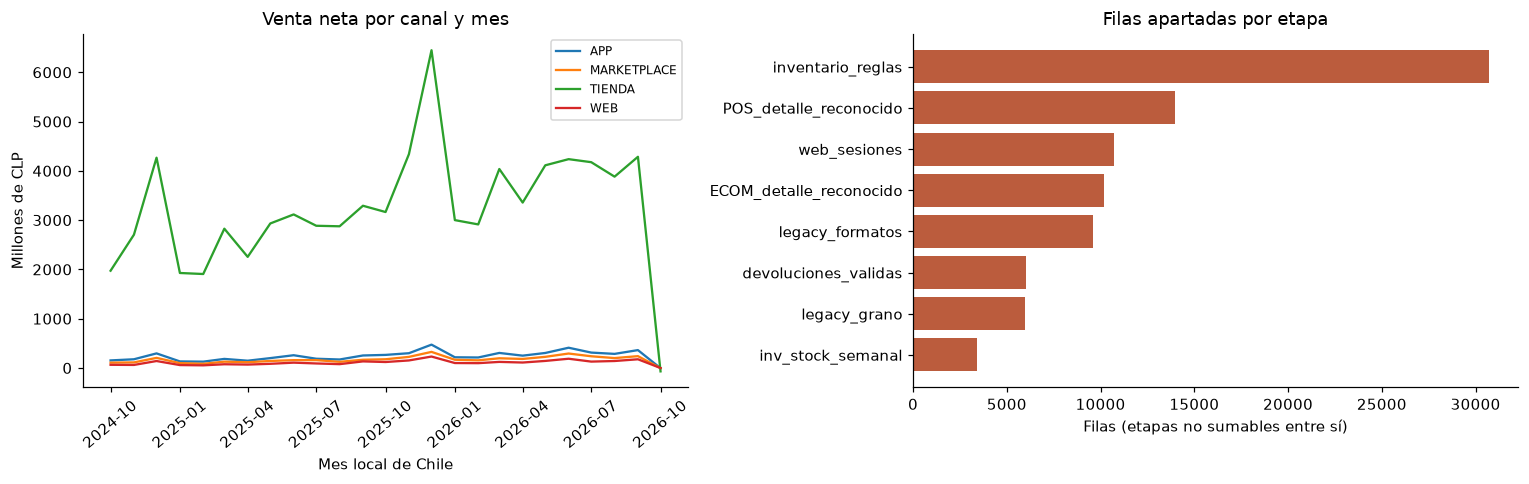

,tabla_destino,medida,regla,fuente,fila_bronze,hash_bronze,fila_cabecera,hash_cabecera
0,dw.fact_ventas,monto_neto,Prorrateo entero del neto reconocido de cabecera,pos_ventas_detalle,0,de88e446d9bf3dfe19e81bd0dae583cf896f910440a6b7...,0,6bcac06e89a517e422814ae92beebc71961b5e85657709...


El manifiesto de la ejecución identifica el archivo Bronze por hash. `_src_row` es su posición de fila en el orden de extracción; las claves naturales permiten relacionar eventos. Los datos personales permanecen en las capas locales restringidas y no se muestran en las evidencias.

In [15]:
# Visualización integrada: series y calidad, con unidades y periodo explícitos.
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
plot=monthly.assign(periodo=pd.to_datetime(dict(year=monthly.anio,month=monthly.mes,day=1)))
for canal,group in plot.groupby('canal'):
    axes[0].plot(group.periodo,group.venta_neta/1_000_000,label=canal)
axes[0].set(title='Venta neta por canal y mes',ylabel='Millones de CLP',xlabel='Mes local de Chile')
axes[0].legend(fontsize=8); axes[0].tick_params(axis='x',rotation=40)
problem=quality_df.loc[quality_df.rechazadas.gt(0)].nlargest(8,'rechazadas')
axes[1].barh(problem.etapa,problem.rechazadas,color='#bb5c3d')
axes[1].set(title='Filas apartadas por etapa',xlabel='Filas (etapas no sumables entre sí)')
axes[1].invert_yaxis();fig.tight_layout()
from io import BytesIO
from IPython.display import Image
chart_buffer=BytesIO();fig.savefig(chart_buffer,format='png',bbox_inches='tight')
fig.savefig(DATA/'gold'/'resumen.png',bbox_inches='tight')
display(Image(data=chart_buffer.getvalue()));plt.close(fig)

# Linaje completo de una medida sin exponer identidad personal.
sample=facts['fact_ventas'].iloc[0]
source_name='pos_ventas_detalle' if sample.fuente=='ventas_POS' else 'ecom_pedidos_detalle'
source_row=raw[source_name].loc[raw[source_name]._src_row.eq(sample._src_row)].iloc[0]
assert source_row._batch==sample._batch
lineage=pd.DataFrame([{'tabla_destino':'dw.fact_ventas','medida':'monto_neto',
    'regla':'Prorrateo entero del neto reconocido de cabecera','fuente':source_name,
    'fila_bronze':int(sample._src_row),'hash_bronze':sample._batch,
    'fila_cabecera':int(sample.cabecera_row),'hash_cabecera':sample.cabecera_batch}])
display(lineage)
display(Markdown('El manifiesto de la ejecución identifica el archivo Bronze por hash. `_src_row` es su posición de fila en el orden de extracción; las claves naturales permiten relacionar eventos. Los datos personales permanecen en las capas locales restringidas y no se muestran en las evidencias.'))

**Interpretación de los gráficos.** El periodo transaccional de referencia termina el 30/09/2026. Los meses posteriores pueden contener solamente devoluciones de ventas anteriores; no deben compararse como meses completos de venta. Las filas apartadas incluyen estados fuera del contrato de reconocimiento (por ejemplo, anulaciones), además de problemas de calidad. Las etapas tienen granos distintos y sus rechazos no se suman como si fueran registros únicos de toda la empresa.

In [16]:
# Diccionario semántico: se genera una fila por columna del modelo.
descriptions={
'monto_neto':('Venta de mercadería sin IVA antes de devoluciones, pesos CLP','venta; ingreso','SUM','No volver a descontar descuento ni IVA.'),
'monto_con_iva':('Mercadería con IVA después del descuento de línea, CLP','importe bruto','SUM','No incluye despacho web.'),
'monto_neto_devuelto':('Importe aprobado a restar de venta, sin IVA, CLP','devolución; reembolso','SUM','Restar una sola vez, según fecha de devolución.'),
'cantidad':('Unidades del evento','unidades; volumen','SUM','Interpretar según la tabla: venta o devolución.'),
'stock_sistema':('Unidades registradas en el corte de inventario','existencias; stock','SUM por corte','Nunca sumar fechas de corte.'),
'stock_fisico':('Unidades contadas; nulo significa no informado','conteo físico','SUM por corte','No reemplazar nulos por cero.'),
'stock_minimo':('Umbral mínimo por producto y sucursal','mínimo','No sumar entre fechas','Comparar con stock del mismo corte.'),
'punto_reposicion':('Umbral operativo para solicitar reposición','reposición','No sumar entre fechas','No confundir con stock mínimo.'),
'unidades_en_transito':('Unidades pendientes de llegada al corte','en tránsito','SUM por corte','No duplicar con órdenes.'),
'diferencia_stock':('Conteo físico menos stock de sistema','diferencia de inventario','SUM por corte','Nulo si no existe conteo.'),
'riesgo_reposicion':('Stock de sistema menor o igual al mínimo','riesgo; bajo mínimo','SUM banderas','Es una alerta, no prueba de quiebre efectivo.'),
'sin_conteo':('No se informó conteo físico','incompleto','SUM banderas','No equivale a stock cero.'),
'conteo_antiguo':('Conteo ausente o mayor a 30 días','desactualizado','SUM banderas','Evaluado respecto del corte.'),
'monto_atribuido':('Importe atribuido por plataforma de marketing, CLP','atribución','SUM','No sumar a ventas ni interpretar como causalidad.'),
'presupuesto_clp':('Presupuesto de campaña en CLP','inversión','Una vez por campaña','No sumarlo después de unir todos sus envíos.'),
'sin_consentimiento':('Envío a registro sin consentimiento vigente informado','consentimiento','SUM banderas','La fuente no tiene historia de consentimiento.'),
'embudo_inconsistente':('Interacción posterior en envío no entregado','embudo inválido','SUM banderas','Excluir de tasas condicionadas a entrega.'),
'entregado':('Envío entregado según plataforma','entrega','SUM banderas','Denominador de conversión reportada.'),
'abierto':('Apertura reportada del envío','apertura','SUM banderas','No es cliente único.'),
'click':('Clic reportado del envío','clic','SUM banderas','No equivale a venta.'),
'convertido':('Conversión reportada del envío','conversión','SUM banderas','Validar entregado; no implica causalidad.'),
'paginas_vistas':('Páginas vistas en la sesión','vistas','SUM','Una sesión por fila.'),
'duracion_seg':('Duración de sesión en segundos','duración','SUM o AVG','Expresar unidades.'),
'agrego_carrito':('La sesión agregó un producto al carrito','carrito','SUM banderas','No es cantidad de productos.'),
'inicio_checkout':('La sesión inició checkout','checkout','SUM banderas','No sumar a sesiones.'),
'compro':('Compra reportada por analítica web','compra web','SUM banderas','No reemplaza los pedidos entregados.'),
'cantidad_solicitada':('Unidades solicitadas en la orden','pedido reposición','SUM','Grano orden.'),
'cantidad_recibida':('Unidades recibidas acumuladas de la orden','recepción','SUM','Snapshot acumulado; no sumar versiones de la orden.'),
'es_actual':('Versión dimensional vigente','actual','No aplica','Para historia unir por clave del hecho, no filtrar actual.'),
'valido_desde':('Inicio inclusivo de vigencia','desde','No aplica','Intervalo [desde,hasta).'),
'valido_hasta':('Fin exclusivo de vigencia','hasta','No aplica','2100 representa fin abierto en el laboratorio.'),
'historia_observada':('Versión creada desde un cambio observado','historia','No aplica','False identifica línea base sin historia reconstruida.'),
'zona_anterior':('Zona previa retenida por SCD3','zona previa','No aplica','Conserva solo un cambio, no historia completa.'),
'_src_row':('Posición de la fila en su instantánea Bronze','linaje','No aplica','Resolver junto con _batch.'),
'_batch':('SHA256 de la instantánea fuente','lote','No aplica','Consultar manifiesto; no es fecha de negocio.'),
'cabecera_row':('Fila de cabecera en Bronze','linaje cabecera','No aplica','Explica el neto distribuido.'),
'cabecera_batch':('SHA256 de instantánea de cabecera','lote cabecera','No aplica','Resolver con manifiesto.'),
'cliente_nk':('Identificador seudonimizado de entidad resuelta','persona','COUNT DISTINCT','No contar versiones SCD como personas.'),
'documento_nk':('Identificador de documento prefijado por sistema','ticket; boleta; pedido','COUNT DISTINCT','No contar líneas para ticket promedio.'),
'region':('Región del rol de la dimensión','territorio','Agrupar','Distinguir región del cliente y de la sucursal.'),
'comuna':('Comuna del rol de la dimensión','localidad','Agrupar','No confundir residencia con lugar de venta.'),
'categoria':('Categoría homologada de producto','familia; rubro','Agrupar','Usar versión histórica enlazada al hecho.'),
'linea':('Línea de negocio','línea','Agrupar','WEB_SIN_HOMOLOGAR conserva incertidumbre.'),
'segmento':('Segmento CRM observado','tipo de cliente','Agrupar','SCD2; no inferir historia anterior.'),
'acepta_marketing':('Consentimiento vigente observado','consentimiento actual','No aplica','No reconstruye consentimiento histórico.'),
}
dictionary=[]
for table,frame in all_frames.items():
    for col in frame:
        if col in descriptions: desc,syn,agg,note=descriptions[col]
        elif col.endswith('_key'):
            desc='Clave sustituta de '+col.removesuffix('_key').replace('_',' ');syn='identificador';agg='No aplica';note='Unir con la dimensión correspondiente; 0 es desconocido/no aplicable.'
        elif col.endswith('_nk'):
            desc='Clave natural del evento o entidad '+col.removesuffix('_nk');syn='identificador de origen';agg='No aplica';note='Respetar el grano declarado.'
        else:
            desc={'fecha':'Fecha de calendario','anio':'Año calendario','mes':'Mes calendario 1–12','dia':'Día del mes','trimestre':'Trimestre calendario 1–4','semana_iso':'Semana ISO','anio_iso':'Año de la semana ISO','producto':'Descripción de producto','marca':'Marca comercial','subcategoria':'Subcategoría de producto','sucursal':'Nombre de sucursal','pais':'País del rol geográfico','zona':'Zona comercial actual','canal':'Canal de venta','codigo_campania':'Código homologado de campaña','nombre_campania':'Nombre de campaña','tipo_campania':'Tipo de campaña','fecha_inicio':'Inicio de campaña','fecha_fin':'Fin de campaña','calidad_campania':'Validez de periodo y presupuesto','dispositivo':'Dispositivo de la sesión','fuente_trafico':'Origen del tráfico web','estado':'Estado actual de la orden','fuente':'Sistema original de venta'}[col]
            syn=col.replace('_',' ');agg='Agrupar / filtrar';note='Atributo descriptivo; no sumar.'
        dictionary.append({'tabla':table,'columna':col,'tipo':str(frame[col].dtype),'descripcion':desc,'sinonimos':syn,'agregacion':agg,'regla_NLQ':note})
dictionary=pd.DataFrame(dictionary)
dictionary.to_parquet(DATA/'gold'/'diccionario_semantico.parquet',index=False)
display(Markdown('### Diccionario completo del modelo'))
from IPython.display import HTML
display(HTML('<details><summary>Ver todas las columnas y sus reglas semánticas</summary>'+dictionary.to_html(index=False,escape=True)+'</details>'))
display(Markdown('''### IA generativa: uso responsable
Ejemplo: **«¿Cuál fue la venta neta mensual por canal?»** se resuelve con la consulta
`monthly`: une ventas y devoluciones con `UNION ALL`, aplica el signo y agrega por mes local.
**«¿Cuántos clientes activos hay?»** usa `COUNT DISTINCT cliente_nk`, no cuenta versiones SCD.
Estas consultas fueron escritas y verificadas; no se afirma haber conectado un modelo generativo.
Una futura integración NLQ debe usar vistas de solo lectura, límites de filas, permisos mínimos,
validación humana de SQL y este diccionario. No enviar RUT, correos ni credenciales a un modelo.
'''))

### Diccionario completo del modelo

tabla,columna,tipo,descripcion,sinonimos,agregacion,regla_NLQ
dim_producto,producto_key,int64,Clave sustituta de producto,identificador,No aplica,Unir con la dimensión correspondiente; 0 es desconocido/no aplicable.
dim_producto,producto_nk,str,Clave natural del evento o entidad producto,identificador de origen,No aplica,Respetar el grano declarado.
dim_producto,producto,str,Descripción de producto,producto,Agrupar / filtrar,Atributo descriptivo; no sumar.
dim_producto,linea,str,Línea de negocio,línea,Agrupar,WEB_SIN_HOMOLOGAR conserva incertidumbre.
dim_producto,categoria,str,Categoría homologada de producto,familia; rubro,Agrupar,Usar versión histórica enlazada al hecho.
dim_producto,subcategoria,str,Subcategoría de producto,subcategoria,Agrupar / filtrar,Atributo descriptivo; no sumar.
dim_producto,marca,str,Marca comercial,marca,Agrupar / filtrar,Atributo descriptivo; no sumar.
dim_producto,valido_desde,datetime64[us],Inicio inclusivo de vigencia,desde,No aplica,"Intervalo [desde,hasta)."
dim_producto,valido_hasta,datetime64[us],Fin exclusivo de vigencia,hasta,No aplica,2100 representa fin abierto en el laboratorio.
dim_producto,es_actual,bool,Versión dimensional vigente,actual,No aplica,"Para historia unir por clave del hecho, no filtrar actual."


### IA generativa: uso responsable
Ejemplo: **«¿Cuál fue la venta neta mensual por canal?»** se resuelve con la consulta
`monthly`: une ventas y devoluciones con `UNION ALL`, aplica el signo y agrega por mes local.
**«¿Cuántos clientes activos hay?»** usa `COUNT DISTINCT cliente_nk`, no cuenta versiones SCD.
Estas consultas fueron escritas y verificadas; no se afirma haber conectado un modelo generativo.
Una futura integración NLQ debe usar vistas de solo lectura, límites de filas, permisos mínimos,
validación humana de SQL y este diccionario. No enviar RUT, correos ni credenciales a un modelo.


In [17]:
# Pruebas de datos y errores: se comprueban propiedades, no solo que el código termine.
checks=[]
def passed(name): checks.append({'prueba':name,'resultado':'OK'})
validate_destination(facts);passed('Grano, PK, FK y medidas no negativas')
assert int(kpi.venta_antes_devoluciones.iloc[0])==int(sales.monto_neto.sum());passed('Cuadratura monetaria Pandas vs SQL Server')
assert int(kpi.venta_neta.iloc[0])==int(monthly.venta_neta.sum());passed('Venta neta vs agregación mensual')
assert quality_df.leidas.eq(quality_df.aceptadas+quality_df.rechazadas+quality_df.duplicadas).all();passed('Balance de filas por etapa')
mini=pd.DataFrame({'doc':['A']*3,'peso':[1,1,1],'neto':[10]*3})
assert list(allocate_integer(mini,'doc','peso','neto'))==[4,3,3];passed('Prorrateo entero con resto')
broken={n:f.head(1).copy() for n,f in facts.items()}
broken['fact_ventas'].loc[:,'fecha_key']=99999999
try:
    validate_destination(broken)
except ValueError: passed('Quality gate detiene FK inválida antes de publicar')
else: raise AssertionError('Se aceptó una clave inválida')
probe='probe_'+uuid.uuid4().hex[:20]
try:
    with DW.begin() as conn:
        conn.execute(text("INSERT INTO ctl.ejecuciones(run_id,estado) VALUES(:id,'TEST')"),{'id':probe})
        raise RuntimeError('Falla controlada para verificar rollback')
except RuntimeError: pass
assert query('SELECT COUNT(*) n FROM ctl.ejecuciones WHERE run_id=:id',{'id':probe}).iloc[0,0]==0
passed('Rollback real en SQL Server ante una excepción')

# Comparar una segunda publicación completa: conteos, importes y claves permanecen iguales.
def destination_signature():
    result={}
    for name in facts:
        value=query(f'SELECT COUNT_BIG(*) n,CHECKSUM_AGG(BINARY_CHECKSUM(*)) checksum FROM dw.{name}').iloc[0].to_dict()
        result[name]=value
    return result
before=destination_signature()
publish(RUN_ID[:24]+'_repeat')
after=destination_signature()
assert before==after
passed('Segunda publicación real: mismos conteos y checksum de contenido')
display(Markdown('El checksum de SQL Server es un control complementario, no una prueba criptográfica: se combina con PK, FK, conteos y conciliación monetaria.'))
for name,nk,sk,t2,t1,t3 in [
    ('dim_cliente','cliente_nk','cliente_key',['comuna','region','segmento'],['acepta_marketing'],[]),
    ('dim_producto','producto_nk','producto_key',['linea','categoria','subcategoria'],['producto','marca'],[]),
    ('dim_sucursal','sucursal_nk','sucursal_key',[],['sucursal','comuna','region','pais'],['zona'])]:
    inc={'dim_cliente':client_master,'dim_producto':product_master,'dim_sucursal':store_master}[name]
    repeated=scd_merge(inc,dimensions[name],nk,sk,t2,t1,t3)
    assert len(repeated)==len(dimensions[name])
    validate_scd(repeated,nk,sk)
passed('Reejecución de SCD sin crear nuevas versiones')
display(pd.DataFrame(checks))

El checksum de SQL Server es un control complementario, no una prueba criptográfica: se combina con PK, FK, conteos y conciliación monetaria.

,prueba,resultado
0,"Grano, PK, FK y medidas no negativas",OK
1,Cuadratura monetaria Pandas vs SQL Server,OK
2,Venta neta vs agregación mensual,OK
3,Balance de filas por etapa,OK
4,Prorrateo entero con resto,OK
5,Quality gate detiene FK inválida antes de publ...,OK
6,Rollback real en SQL Server ante una excepción,OK
7,Segunda publicación real: mismos conteos y che...,OK
8,Reejecución de SCD sin crear nuevas versiones,OK


In [18]:
# Optimización medida: formatos y selección de columnas; los tiempos no prometen aceleración.
measure=facts['fact_ventas'][['fecha_key','producto_key','cantidad','monto_neto']]
csv_path=DATA/'gold'/'comparacion_ventas.csv';pq_path=DATA/'gold'/'comparacion_ventas.parquet'
measure.to_csv(csv_path,index=False);measure.to_parquet(pq_path,index=False)
times=[]
for fmt,path,read in [('CSV',csv_path,lambda:pd.read_csv(csv_path,usecols=['monto_neto'])),
                      ('Parquet',pq_path,lambda:pd.read_parquet(pq_path,columns=['monto_neto']))]:
    durations=[]
    for _ in range(3):
        start=time.perf_counter(); loaded=read(); durations.append(time.perf_counter()-start)
    assert int(loaded.monto_neto.sum())==int(measure.monto_neto.sum())
    times.append({'formato':fmt,'bytes':path.stat().st_size,'lectura_mediana_seg':float(np.median(durations))})
display(pd.DataFrame(times))

# Plan de ejecución real: la inspección no ejecuta la consulta ni altera índices.
odbc=DW.raw_connection()
try:
    cursor=odbc.cursor();cursor.execute('SET SHOWPLAN_XML ON')
    cursor.execute('SELECT SUM(monto_neto) FROM dw.fact_ventas WHERE fecha_key BETWEEN 20260901 AND 20260930')
    plan_xml=cursor.fetchone()[0]
    cursor.execute('SET SHOWPLAN_XML OFF'); cursor.close()
finally: odbc.close()
(DATA/'control'/'plan_consulta.xml').write_text(plan_xml,encoding='utf-8')
print('Plan SQL Server capturado. Usa operador Index Seek:', 'Index Seek' in plan_xml)
timings=[]
queries={
 'Hecho detallado':'''SELECT d.anio,d.mes,f.canal_key,SUM(f.monto_neto) importe
 FROM dw.fact_ventas f JOIN dw.dim_fecha d ON f.fecha_key=d.fecha_key GROUP BY d.anio,d.mes,f.canal_key''',
 'Agregado persistido':'''SELECT anio,mes,canal_key,venta_sin_devoluciones importe FROM dw.gold_ventas_mes'''}
reference=None
for label,sql in queries.items():
    durations=[]
    for _ in range(3):
        start=time.perf_counter(); result=query(sql);durations.append(time.perf_counter()-start)
    result=result.sort_values(['anio','mes','canal_key']).reset_index(drop=True)
    if reference is None: reference=result
    else: pd.testing.assert_frame_equal(reference,result,check_dtype=False)
    timings.append({'consulta':label,'mediana_seg':float(np.median(durations)),'filas':len(result)})
display(pd.DataFrame(timings))
display(Markdown('''Los tiempos corresponden al equipo local y tres lecturas, con posible caché.
Los índices aceleran filtros a cambio de espacio y costo de escritura. El agregado mensual
reduce filas consultadas y se refresca tras la publicación. El particionamiento implementado
es de **archivos Parquet**; no se afirma particionar tablas de SQL Server.
Delta Lake y ADLS son alternativas de evolución, no componentes ejecutados de esta solución.
Parquet por sí solo no aporta transacciones ACID ni time travel: este trabajo es DWH + capas de archivos.
'''))

,formato,bytes,lectura_mediana_seg
0,CSV,14295827,0.046950
1,Parquet,2172193,0.007704


Plan SQL Server capturado. Usa operador Index Seek: False


,consulta,mediana_seg,filas
0,Hecho detallado,0.054461,96
1,Agregado persistido,0.002291,96


Los tiempos corresponden al equipo local y tres lecturas, con posible caché.
Los índices aceleran filtros a cambio de espacio y costo de escritura. El agregado mensual
reduce filas consultadas y se refresca tras la publicación. El particionamiento implementado
es de **archivos Parquet**; no se afirma particionar tablas de SQL Server.
Delta Lake y ADLS son alternativas de evolución, no componentes ejecutados de esta solución.
Parquet por sí solo no aporta transacciones ACID ni time travel: este trabajo es DWH + capas de archivos.


In [19]:
# Evidencia y conclusiones calculadas a partir de la ejecución verificada.
unknowns=pd.DataFrame([{'dimension':c,'lineas_sin_resolver':int(facts['fact_ventas'][c].eq(0).sum()),
                       'porcentaje':round(100*facts['fact_ventas'][c].eq(0).mean(),2)}
                      for c in ['producto_key','sucursal_key','cliente_key','campania_key']])
display(unknowns)
display(Markdown('Campaña 0 también significa ausencia de campaña; no todo miembro 0 constituye un error. Cliente 0 puede representar compra anónima.'))
display(controls['definiciones_kpi_por_area'])
display(Markdown('### Reportes manuales: cobertura independiente'))
legacy_summary=legacy.assign(anio=legacy.fecha_limpia.dt.year).groupby('anio').agg(filas=('fecha_limpia','size'),importe_reportado=('monto_limpio','sum')).reset_index()
display(legacy_summary)
display(Markdown('Los importes legacy conservan su definición original; no se declaran venta neta sin IVA. Las fechas ambiguas quedan en cuarentena. Su conciliación financiera exige confirmar el criterio y periodo de cada archivo; no se incorporan al hecho transaccional.'))

summary=f'''### Conclusiones de la ejecución
- Se extrajeron **{int(inventory.filas.sum()):,}** registros de 16 fuentes dentro de una instantánea de solo lectura.
- Se publicaron **{len(facts['fact_ventas']):,} líneas de venta** y cinco hechos complementarios en SQL Server.
- La venta reconocida antes de devoluciones fue **{int(kpi.venta_antes_devoluciones.iloc[0]):,} CLP**;
  las devoluciones netas aceptadas fueron **{int(kpi.devoluciones_netas.iloc[0]):,} CLP**.
  La venta neta resultante es **{int(kpi.venta_neta.iloc[0]):,} CLP**, bajo el contrato documentado.
- Se verificaron **{len(checks)} controles**, incluida una segunda publicación real sin duplicados
  y rollback transaccional ante una excepción controlada.
- La calidad mejora al homologar, separar conflictos y conservar rechazos. No significa que
  todos los datos originales sean correctos: persisten identidades no resueltas y supuestos financieros.

### Límites y siguientes pasos
La historia SCD comienza con observaciones del pipeline: la fuente no entrega cambios históricos.
Los estados actuales de pedidos no permiten reconstruir toda su evolución; se excluyen DEVUELTO
del reconocimiento para evitar doble descuento. Confirmar con Finanzas si se requiere reconocer
la venta original y su reversa, así como la base tributaria de los reembolsos.
No hay autenticación de usuarios analíticos implementada en este notebook: la conexión del laboratorio
usa Windows; en producción se separarían cuentas de lectura, carga y consumo.
El log no imprime datos personales, pero Bronze/Silver requieren permisos de carpeta y retención.
No se publicaron datos ni código en GitHub. El historial Git local documenta el desarrollo real.
'''
display(Markdown(summary))
history=subprocess.run(['git','log','--format=%h %s','-12'],capture_output=True,text=True,encoding='utf-8',errors='replace',check=True).stdout
print('Historial local al ejecutar el notebook:\n'+history)
LOG.info('Fin run=%s pruebas=%d',RUN_ID,len(checks))
PG.dispose();DW.dispose()

,dimension,lineas_sin_resolver,porcentaje
0,producto_key,0,0.00
1,sucursal_key,10499,1.68
2,cliente_key,272079,43.44
3,campania_key,549301,87.71


Campaña 0 también significa ausencia de campaña; no todo miembro 0 constituye un error. Cliente 0 puede representar compra anónima.

,kpi,area,definicion_actual,fuente_que_usa,observacion
0,Venta neta del mes,Comercial,Suma de monto_total de boletas y facturas del ...,pos_ventas_cabecera,No incluye e-commerce; incluye boletas duplica...
1,Venta neta del mes,Finanzas,Suma de monto_neto (sin IVA) de documentos EMI...,"pos_ventas_cabecera, ecom_pedidos, devoluciones",Usa fecha local de Chile
2,Venta neta del mes,Marketing,Total pagado de pedidos web (cualquier estado ...,"ecom_pedidos, pos_ventas_cabecera",Corta el mes con fecha_pedido_utc (desfase de ...
3,Cliente activo,Marketing,Cliente con apertura o clic de campaña en los ...,mkt_envios_campania,"Cuenta registros CRM, no personas (duplicados)"
4,Cliente activo,Comercial,RUT con al menos una compra en tienda en los ú...,pos_ventas_cabecera,RUT escrito en distintos formatos
5,Cliente activo,CRM,estado = ACTIVO en crm_clientes,crm_clientes,No se actualiza con la actividad real
6,Ticket promedio,Comercial,Suma monto_total / cantidad de boletas (incluy...,pos_ventas_cabecera,NaN
7,Ticket promedio,Finanzas,"Suma monto_neto / documentos válidos, sin fact...",pos_ventas_cabecera,NaN
8,Rotación de productos,Operaciones,Unidades vendidas en 4 semanas / stock promedi...,"pos_ventas_detalle, inv_stock_semanal",Usa stock_sistema
9,Rotación de productos,Comercial,Semanas de cobertura = stock_fisico actual / v...,"pos_ventas_detalle, inv_stock_semanal",NaN


### Reportes manuales: cobertura independiente

,anio,filas,importe_reportado
0,2023,27768,555635468687.0
1,2024,22922,607466720506.0


Los importes legacy conservan su definición original; no se declaran venta neta sin IVA. Las fechas ambiguas quedan en cuarentena. Su conciliación financiera exige confirmar el criterio y periodo de cada archivo; no se incorporan al hecho transaccional.

### Conclusiones de la ejecución
- Se extrajeron **3,438,326** registros de 16 fuentes dentro de una instantánea de solo lectura.
- Se publicaron **626,285 líneas de venta** y cinco hechos complementarios en SQL Server.
- La venta reconocida antes de devoluciones fue **96,631,960,338 CLP**;
  las devoluciones netas aceptadas fueron **2,821,196,960 CLP**.
  La venta neta resultante es **93,810,763,378 CLP**, bajo el contrato documentado.
- Se verificaron **9 controles**, incluida una segunda publicación real sin duplicados
  y rollback transaccional ante una excepción controlada.
- La calidad mejora al homologar, separar conflictos y conservar rechazos. No significa que
  todos los datos originales sean correctos: persisten identidades no resueltas y supuestos financieros.

### Límites y siguientes pasos
La historia SCD comienza con observaciones del pipeline: la fuente no entrega cambios históricos.
Los estados actuales de pedidos no permiten reconstruir toda su evolución; se excluyen DEVUELTO
del reconocimiento para evitar doble descuento. Confirmar con Finanzas si se requiere reconocer
la venta original y su reversa, así como la base tributaria de los reembolsos.
No hay autenticación de usuarios analíticos implementada en este notebook: la conexión del laboratorio
usa Windows; en producción se separarían cuentas de lectura, carga y consumo.
El log no imprime datos personales, pero Bronze/Silver requieren permisos de carpeta y retención.
No se publicaron datos ni código en GitHub. El historial Git local documenta el desarrollo real.


Historial local al ejecutar el notebook:
e486599 test: verifica publicacion repetida y completa documentacion EP3
570e44f feat: incorpora indicadores y capa semantica con pruebas
bf5b7b8 feat: construye hechos y carga transaccional en SQL Server
7bf568a feat: implementa dimensiones y SCD
8a73d9d feat: implementa calidad e integracion silver
a153393 feat: incorpora extraccion y capa bronze
1099ac7 docs: define fuentes y modelo dimensional
9989a06 docs: registra alcance y plan de la EP3



## 8. Decisiones de arquitectura y evaluación final

### Justificación de la carga completa
La fuente no ofrece un registro confiable de modificaciones por evento: `_fecha_carga` no es
necesariamente una fecha de actualización de negocio. Filtrar únicamente por esa columna podría
omitir anulaciones y correcciones. Por eso se implementa **recarga completa controlada**, con
historia dimensional persistente, PK/FK, bloqueo de publicación y transacción.
Una evolución incremental requeriría CDC o un contrato de actualización, manejo de eventos tardíos
y una marca de agua que avance solo después de una publicación exitosa.

La transformación se realiza en Pandas; SQL Server almacena el modelo y calcula agregados SQL.
La extracción previa de crudos no convierte todo el proceso en ELT. SSIS/ADF podrían orquestar
las mismas responsabilidades, pero no se afirma haberlos utilizado.

### Mejoras respecto de los notebooks del curso
| Material base | Mejora implementada |
|---|---|
| Diseño dimensional 2.1.4 | Constelación de hechos con grano explícito, dimensiones compartidas, PK/FK y SCD 1/2/3 probados |
| Pipeline 2.2.3 | Fuentes reales, contrato de columnas, resolución conservadora, cuarentena, logging y transacciones |
| Pipeline 2.2.3 | Deduplicación por claves de negocio, no por fecha+SKU+sucursal; prorrateo exacto y devoluciones trazables |
| Parquet 2.4.4 | Capas persistidas, particiones de archivos, lectura selectiva y medición sobre datos del caso |
| Guías de robustez | Manifiesto por corrida, linaje de cabecera/detalle, pruebas de rollback y segunda publicación |

### Matriz de cumplimiento verificable
| Criterio de pauta | Evidencia en este notebook |
|---|---|
| Modelo (20%) | Sección 1, Bus Matrix, diagrama editable, grano, atributos y diccionario completo |
| SCD (20%) | Sección 4, merge de dimensiones, intervalos sin solapamiento, prueba del límite temporal y reejecución |
| ETL (20%) | Secciones 2–5, extracción PostgreSQL, contratos, reglas, cuarentena, logging y conciliación |
| Almacenamiento (20%) | Sección 6, SQL Server persistente, Bronze/Silver/Gold, PK/FK y publicación transaccional |
| Documentación (20%) | Portada, decisiones, salidas ejecutadas, pruebas, conclusiones, referencias e historial Git |

Esta matriz indica dónde revisar la evidencia; no sustituye la calificación del docente.
El formato de entrega final debe respetar lo que el docente indique. El notebook integra
el informe y el desarrollo; `modelo.drawio` se conserva como apoyo editable.

## 9. Bibliografía y referencias del material proporcionado

1. Duoc UC. **EP3_Instrucciones y Pauta_Encargo_Estudiante**. IDY1102. Indicadores y rúbrica de esta entrega.
2. **Caso de Negocio: DataRetail 360**. Problemática, necesidades y preguntas analíticas.
3. **dataretail360_estructura.sql**. Contrato de estructuras del origen; complementado con inspección de la base poblada.
4. **2.1.1 PPT Modelado Dimensional y Capa Semántica IA**, **2.1.2 Guía Dimensiones Espaciales**, **2.1.3 Bus Matrix** y **2.1.5 Diccionario de Datos para IA**.
5. **2.1.4 Notebook Diseño Dimensional Práctico**. Base de diseño estrella y SCD2.
6. **2.2.1 PPT ETL/ELT con Python y SSIS**, **2.2.2 Guía SQL Server + SSMS**, **2.2.3 Notebook Pipeline Pandas**.
7. **2.3.1 Pipelines Robustos**, **2.3.2 Guía Git y GitHub**, **2.3.3 Plantilla README**, **2.3.4 Checklist Code Review**.
8. **2.4.1 Data Lake, Lakehouse y Arquitectura Medallion**, **2.4.2 Guía ADLS**, **2.4.4 Notebook Parquet y Delta Lake con Python**.
9. **2.5.1 Integración y Optimización del DWH** y **2.5.2 Guía Índices, Particionamiento y Vistas Materializadas**.

Los materiales contienen algunas menciones a EP2; la pauta EP3 suministrada rige este trabajo.
Las implementaciones se adaptaron al esquema y datos inspeccionados, sin copiar automáticamente
las simplificaciones de los ejemplos ni presentar alternativas conceptuales como ejecutadas.